# Bacterial Population Growth: Differential Equations and Scientific Computing

### A beginner-friendly Python investigation using the logistic growth model

**Level:** First-year Mathematics degree  
**Topics:** Ordinary differential equations (ODEs), analytical solutions, numerical methods, parameter estimation, data visualization and scientific computing.

---

## Learning objectives

By the end of this notebook, you should be able to:

1. Formulate a population-growth problem as a first-order ordinary differential equation.
2. Explain the meaning of the parameters in the logistic growth model.
3. Derive and use the analytical solution of the logistic equation.
4. Generate simulated observations with measurement noise.
5. Estimate unknown model parameters from data using nonlinear least squares.
6. implement Euler's method to approximate an ODE solution.
7. Compare numerical approximations with an analytical solution.
8. Calculate when the population reaches a specified proportion of its carrying capacity.

## The scientific problem

Imagine that a scientist places an initial population of **40 bacteria** in a controlled laboratory environment. The bacteria reproduce, but nutrients and physical space are limited. Therefore, the population cannot increase indefinitely.

We want to investigate:

- How does the bacterial population change with time?
- What is the maximum population that the environment can support?
- Can we estimate the growth parameters from observed data?
- How accurately can Euler's method approximate the solution?

We will use a mathematical model, generate simulated experimental observations, estimate unknown parameters and perform numerical simulations.

> **Important:** The observations in this notebook are artificially generated from a known mathematical model, with random noise added to imitate measurement errors. They are not actual laboratory data.

---

## Step 0. Install the required Python libraries

We use three Python libraries:

| Library | Purpose |
|---|---|
| NumPy | Numerical calculations, arrays and mathematical functions |
| Matplotlib | Plotting graphs and visualizing results |
| SciPy | Scientific computing, including nonlinear parameter estimation |

The installation command below is written for a Jupyter Notebook. The `%` symbol makes it a notebook magic command.

Run this cell once if the libraries are not already installed in your Python environment.

In [1]:
%pip install numpy matplotlib scipy

---

# Step 1. Formulate the mathematical model

## 1.1 The logistic growth equation

A simple model of unrestricted population growth is exponential growth:

$$
\frac{dP}{dt}=rP.
$$

Here:

- $P(t)$ is the population at time $t$.
- $r$ is the intrinsic growth rate.
- $t$ represents time.

This model assumes that the population can continue growing without any limitation. However, a real bacterial culture has limited nutrients and space.

To account for these limitations, we introduce the **logistic growth model**:

$$
\boxed{\frac{dP}{dt}=rP\left(1-\frac{P}{K}\right)}
$$

with the initial condition

$$
\boxed{P(0)=P_0=40.}
$$

The parameters are:

| Symbol | Meaning | Value or interpretation |
|---|---|---|
| $P(t)$ | Bacterial population at time $t$ | Unknown function |
| $P_0$ | Initial population | 40 |
| $r$ | Intrinsic growth rate | 0.35 per day in our simulated example |
| $K$ | Carrying capacity | 800 in our simulated example |
| $t$ | Time | Measured in days |

The carrying capacity $K$ represents the population level that the environment can sustain in this simplified model.

## 1.2 Understanding the two factors

The right-hand side of the equation contains two factors:

$$
\frac{dP}{dt}
=
\underbrace{rP}_{\text{potential growth}}
\underbrace{\left(1-\frac{P}{K}\right)}_{\text{resource limitation}}.
$$

**First factor: $rP$**

This represents the potential growth rate. If the population is larger, more bacteria are available to reproduce.

**Second factor: $1-P/K$**

This represents the limitation caused by available resources.

Consider three situations:

1. When $P$ is much smaller than $K$, the limiting factor is close to 1. Growth is approximately exponential.
2. When $P$ approaches $K$, the limiting factor approaches 0. Growth slows down.
3. When $P=K$, the growth rate is zero.

At equilibrium,

$$
rP\left(1-\frac{P}{K}\right)=0.
$$

Therefore, the equilibrium populations are

$$
\boxed{P=0 \quad \text{or} \quad P=K.}
$$

For a positive initial population, the model predicts that the population approaches $K$.

## 1.3 What type of differential equation is this?

The logistic model is:

- An ordinary differential equation (ODE), because it involves an ordinary derivative with respect to time.
- First order, because the highest derivative is $dP/dt$.
- Nonlinear, because the right-hand side contains $P^2$ when expanded.
- An initial value problem (IVP), because an initial condition $P(0)=40$ is specified.

---

# Step 2. Derive the analytical solution

Before using Python, we can solve the logistic differential equation mathematically.

Start with

$$
\frac{dP}{dt}=rP\left(1-\frac{P}{K}\right).
$$

### 2.1 Separate the variables

Rewrite the equation as

$$
\frac{dP}{P(1-P/K)}=r\,dt.
$$

Since

$$
\frac{1}{P(1-P/K)}
=
\frac{K}{P(K-P)}
=
\frac{1}{P}+\frac{1}{K-P},
$$

we obtain

$$
\int\left(\frac{1}{P}+\frac{1}{K-P}\right)dP
=
\int r\,dt.
$$

Integrating gives

$$
\ln|P|-\ln|K-P|=rt+C.
$$

Combining the logarithms,

$$
\ln\left|\frac{P}{K-P}\right|=rt+C.
$$

### 2.2 Apply the initial condition

After rearranging and using $P(0)=P_0$, the solution can be written as

$$
P(t)=\frac{K}{1+A e^{-rt}},
$$

where

$$
A=\frac{K-P_0}{P_0}.
$$

Therefore, the analytical solution is

$$
\boxed{
P(t)=
\frac{K}
{1+\left(\frac{K-P_0}{P_0}\right)e^{-rt}}
}
$$

For our problem,

$$
P(t)=
\frac{800}
{1+19e^{-0.35t}}
$$

when $P_0=40$, $r=0.35$ and $K=800$.

This analytical solution will be useful later because we can compare it with the numerical approximation produced by Euler's method.

### 2.3 Why do we implement the analytical solution in Python?

The function below evaluates the mathematical expression for any specified time $t$.

For example, it can calculate the predicted population at day 0, day 5 or day 20.

We use NumPy's `np.exp()` function to calculate the exponential term $e^{-rt}$.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Initial conditions and true parameters used to generate simulated data
P0 = 40
r_true = 0.35
K_true = 800

# Analytical solution of the logistic differential equation
def logistic(t, r, K):
    A = (K - P0) / P0
    return K / (1 + A * np.exp(-r * t))

# Test the analytical solution at t = 0
print("Population at day 0:", logistic(0, r_true, K_true))

# Test the analytical solution at t = 10
print("Population at day 10:", logistic(10, r_true, K_true))

Population at day 0: 40.0
Population at day 10: 508.3398602769903


### Mathematical interpretation of the code

The function

```python
def logistic(t, r, K):
```

defines a mathematical function with three inputs:

- `t`: time;
- `r`: growth-rate parameter;
- `K`: carrying-capacity parameter.

The line

```python
A = (K - P0) / P0
```

calculates

$$
A=\frac{K-P_0}{P_0}.
$$

The return statement

```python
return K / (1 + A * np.exp(-r * t))
```

implements

$$
P(t)=\frac{K}{1+Ae^{-rt}}.
$$

The function can accept a single time value or an array of time values. This is useful for calculating a whole population-growth curve efficiently.

At $t=0$,

$$
P(0)=\frac{K}{1+\frac{K-P_0}{P_0}}=P_0.
$$

Thus, the analytical solution satisfies the specified initial condition.

---

# Step 3. Generate simulated experimental observations

In a real laboratory, a scientist might measure the bacterial population every two days. These measurements will not usually follow a perfectly smooth mathematical curve because of measurement errors and natural variation.

We imitate this situation by generating data from the logistic model and adding random noise.

## 3.1 Select observation times

We use

$$
t=0,2,4,6,8,10,12,14,16,18.
$$

In Python:

```python
t_data = np.arange(0, 20, 2)
```

The function `np.arange(start, stop, step)` generates equally spaced values. The stop value, 20, is excluded.

## 3.2 Add measurement noise

We assume that the observed population is

$$
P_{\text{observed}}(t_i)
=
P_{\text{model}}(t_i)+\varepsilon_i,
$$

where the measurement error is modelled as

$$
\varepsilon_i\sim N(0,10^2).
$$

This means that the errors are generated from a normal distribution with:

- Mean $0$: the noise does not systematically increase or decrease the measurements.
- Standard deviation $10$: the typical size of the random error is approximately 10 population units.

We use a random seed of 12 so that the same simulated observations can be reproduced whenever the notebook is run.

The first observation is then set exactly to $P_0=40$, because the initial population is assumed to be known.

In [3]:
# Create a reproducible random number generator
rng = np.random.default_rng(12)

# Observation times: 0, 2, 4, ..., 18 days
t_data = np.arange(0, 20, 2)

# Generate ideal observations from the logistic model
P_data = logistic(t_data, r_true, K_true)

# Add normally distributed measurement noise
P_data += rng.normal(0, 10, len(t_data))

# The initial population is known exactly
P_data[0] = P0

# Display the simulated observations
print("Time (days)    Observed population")
for t, p in zip(t_data, P_data):
    print(f"{t:10.0f}    {p:20.2f}")

Time (days)    Observed population
         0                   40.00
         2                   87.13
         4                  148.13
         6                  247.72
         8                  387.35
        10                  496.28
        12                  616.34
        14                  687.63
        16                  746.40
        18                  783.02


### Mathematical interpretation of the code

**Random number generator**

```python
rng = np.random.default_rng(12)
```

This creates a reproducible random number generator. The number 12 is a seed. It does not change the mathematical model; it ensures that the same random sequence is generated when the code is run again.

**Ideal model observations**

```python
P_data = logistic(t_data, r_true, K_true)
```

This evaluates the analytical solution at every observation time:

$$
P_{\text{model}}(t_i)
=
\frac{K}{1+\left(\frac{K-P_0}{P_0}\right)e^{-rt_i}}.
$$

**Random measurement error**

```python
P_data += rng.normal(0, 10, len(t_data))
```

This adds a different random error to each observation:

$$
P_i=P_{\text{model}}(t_i)+\varepsilon_i.
$$

**Known initial population**

```python
P_data[0] = P0
```

Python uses index 0 for the first element of an array. This line ensures that the first observation is exactly 40.

The resulting observations are not perfectly smooth. This is intentional: parameter estimation will use these noisy observations to recover estimates of the unknown growth parameters.

---

# Step 4. Estimate the unknown parameters

In an actual experiment, we may know the initial population but not know the exact growth rate $r$ or carrying capacity $K$.

We therefore want to estimate these parameters using the observed data.

This is an example of an **inverse problem**.

- A forward problem starts with the model parameters and calculates the population.
- An inverse problem starts with observations and attempts to recover the model parameters.

## 4.1 Mathematical formulation

Our model is

$$
P(t_i;r,K)=
\frac{K}{1+\left(\frac{K-P_0}{P_0}\right)e^{-rt_i}}.
$$

For each observation time $t_i$, we have an observed value $P_i$.

The model prediction is

$$
\widehat P_i=P(t_i;r,K).
$$

The residual is the difference between the observation and prediction:

$$
e_i=P_i-\widehat P_i.
$$

We estimate $r$ and $K$ by minimizing the sum of squared residuals:

$$
\boxed{
\min_{r,K}
\sum_{i=1}^{n}
\left[
P_i-P(t_i;r,K)
\right]^2
}
$$

This is called **nonlinear least-squares parameter estimation**.

It is nonlinear because the unknown parameters occur inside the exponential function and the denominator.

## 4.2 Use SciPy's `curve_fit()`

The function `curve_fit()` from `scipy.optimize` performs nonlinear least-squares fitting.

Its main inputs are:

- `logistic`: the mathematical model to fit;
- `t_data`: the observation times;
- `P_data`: the observed populations;
- `p0`: initial guesses for the parameters;
- `bounds`: lower and upper limits for the parameters.

We use initial guesses $r=0.25$ and $K=750$. These are starting values for the optimization algorithm, not the final answers.

We also impose

$$
0.001\leq r\leq 2
$$

and

$$
P_0+1\leq K\leq 5000.
$$

These constraints ensure that the fitted growth rate is positive and the carrying capacity is greater than the initial population.

In [4]:
# Estimate the unknown growth rate and carrying capacity
parameters, covariance = curve_fit(
    logistic,
    t_data,
    P_data,
    p0=[0.25, 750],
    bounds=([0.001, P0 + 1], [2, 5000])
)

# Extract the estimated parameters
r_est, K_est = parameters

print("Estimated growth rate:", round(r_est, 3))
print("Estimated carrying capacity:", round(K_est, 2))

Estimated growth rate: 0.35
Estimated carrying capacity: 797.19


### Mathematical interpretation of the output

The optimization algorithm searches for values of $r$ and $K$ that make the model predictions as close as possible to the observed data in the least-squares sense.

The output is approximately:

$$
r_{\text{est}}\approx 0.350
$$

and

$$
K_{\text{est}}\approx 797.19.
$$

The values used to generate the simulated observations were

$$
r_{\text{true}}=0.35,\qquad K_{\text{true}}=800.
$$

The estimated values are close to the original values. They are not necessarily identical because random measurement noise was added.

The second output from `curve_fit()` is the estimated covariance matrix of the fitted parameters. In this notebook we store it as `covariance`, although we do not yet use it. It can be used for a more advanced discussion of parameter uncertainty.

---

# Step 5. Implement Euler's numerical method

We now solve the logistic differential equation numerically.

The analytical solution is available for this particular model. However, many differential equations encountered in science and engineering do not have a convenient closed-form solution.

Numerical methods allow us to approximate their solutions.

## 5.1 General Euler formula

Consider a first-order initial value problem:

$$
\frac{dy}{dt}=f(t,y),\qquad y(0)=y_0.
$$

Euler's method approximates the derivative using a forward difference:

$$
\frac{dy}{dt}\approx
\frac{y_{n+1}-y_n}{h},
$$

where $h$ is the time step.

Substituting this approximation into the differential equation gives

$$
\frac{y_{n+1}-y_n}{h}
\approx f(t_n,y_n).
$$

Rearranging,

$$
\boxed{y_{n+1}=y_n+h f(t_n,y_n).}
$$

This formula means that the next approximate value is calculated using the current value and the slope at the current point.

## 5.2 Apply Euler's method to the logistic equation

For our model,

$$
f(P)=rP\left(1-\frac{P}{K}\right).
$$

Therefore,

$$
\boxed{
P_{n+1}
=
P_n+
hrP_n\left(1-\frac{P_n}{K}\right).
}
$$

The initial approximation is

$$
P_0=40.
$$

Using the original illustrative parameters $r=0.35$, $K=800$, and $h=1$ day, the first Euler step is

$$
\begin{aligned}
P_1
&=40+(1)(0.35)(40)
\left(1-\frac{40}{800}\right)\\
&=40+14(0.95)\\
&=\boxed{53.3}.
\end{aligned}
$$

Thus, Euler's method estimates the population after one day as 53.3.

Notice that this is an approximation. The analytical solution gives the exact mathematical-model value at day 1.

## 5.3 Understand the time step

The time step $h$ controls the interval between successive calculations.

For example:

- $h=2$: calculate every two days;
- $h=0.5$: calculate every half day;
- $h=0.1$: calculate every one-tenth of a day.

A smaller step size usually gives a more accurate Euler approximation for this problem, but it requires more calculations.

In [5]:
# Euler's method for the logistic differential equation
def euler_method(r, K, P0, h, T):

    # Calculate the number of time steps
    steps = int(round(T / h))

    # Create the time grid from 0 to T
    t = np.linspace(0, T, steps + 1)

    # Create an array to store the population approximations
    P = np.zeros(steps + 1)

    # Apply the initial condition
    P[0] = P0

    # Calculate each successive population value
    for n in range(steps):

        P[n+1] = P[n] + h * r * P[n] * (
            1 - P[n] / K
        )

    return t, P

### Mathematical interpretation of the Euler code

**Number of steps**

```python
steps = int(round(T / h))
```

The total time interval is $T$, and each step has length $h$. Therefore,

$$
N=\frac{T}{h}.
$$

For $T=24$ and $h=0.5$,

$$
N=\frac{24}{0.5}=48.
$$

There will be 48 calculation steps and 49 stored points, including the initial point.

**Time grid**

```python
t = np.linspace(0, T, steps + 1)
```

This creates equally spaced time values from 0 to $T$, including both endpoints.

**Population array**

```python
P = np.zeros(steps + 1)
```

This creates an array to store the approximated populations. Initially, all entries are zero.

**Initial condition**

```python
P[0] = P0
```

This sets the first entry to the known initial population of 40.

**Euler update**

```python
P[n+1] = P[n] + h * r * P[n] * (1 - P[n] / K)
```

This implements

$$
P_{n+1}
=
P_n+hrP_n\left(1-\frac{P_n}{K}\right).
$$

The loop calculates the next population using the current population. It repeats until the end of the selected time interval.

**Return values**

```python
return t, P
```

The function returns two arrays:

- `t`: the time points;
- `P`: the corresponding numerical population approximations.

This allows us to plot and compare the numerical solution with the analytical solution.

---

# Step 6. Simulate and visualize the population growth

We now combine the observed data, the fitted analytical model and Euler's numerical approximations in one graph.

The graph will contain four types of information:

1. **Experimental observations:** the simulated noisy data.
2. **Fitted logistic model:** the analytical solution using estimated parameters.
3. **Euler approximation with $h=2$:** a relatively large time step.
4. **Euler approximation with $h=0.5$:** a smaller time step.

We also draw a horizontal line at the estimated carrying capacity.

## Mathematical interpretation

The fitted analytical curve is

$$
P(t)=
\frac{K_{\text{est}}}
{1+\left(\frac{K_{\text{est}}-P_0}{P_0}\right)
e^{-r_{\text{est}}t}}.
$$

The Euler curves use the same estimated parameters, but calculate the solution through repeated numerical updates.

Comparing these curves allows us to see the difference between the exact solution of the fitted mathematical model and its numerical approximation.

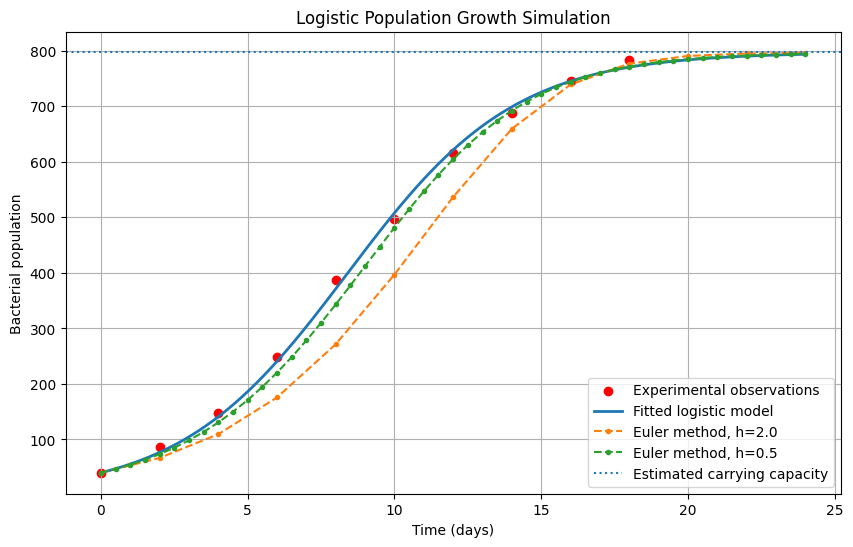

In [6]:
plt.figure(figsize=(10, 6))

# Plot the simulated experimental observations
plt.scatter(
    t_data, P_data,
    color="red",
    label="Experimental observations"
)

# Plot the fitted analytical logistic model
t_fine = np.linspace(0, 24, 300)

plt.plot(
    t_fine,
    logistic(t_fine, r_est, K_est),
    label="Fitted logistic model",
    linewidth=2
)

# Plot Euler approximations for two different step sizes
for h in [2.0, 0.5]:

    t, P = euler_method(
        r_est, K_est, P0, h, 24
    )

    plt.plot(
        t, P,
        "--",
        marker="o",
        markersize=3,
        label=f"Euler method, h={h}"
    )

# Show the estimated carrying capacity
plt.axhline(
    K_est,
    linestyle=":",
    label="Estimated carrying capacity"
)

plt.xlabel("Time (days)")
plt.ylabel("Bacterial population")
plt.title("Logistic Population Growth Simulation")

plt.legend()
plt.grid()
plt.show()

### How should we interpret the graph?

**1. The overall S-shaped curve**

The population initially grows slowly, then increases more rapidly, and finally slows as it approaches the carrying capacity.

**2. The red observations**

The points do not lie exactly on the fitted curve because random measurement noise was added.

**3. The fitted logistic model**

The smooth curve represents the model after estimating $r$ and $K$ from the simulated observations.

**4. The Euler approximations**

The dashed curves represent numerical solutions. They approximate the fitted analytical solution.

A smaller step size generally produces a closer approximation for this example.

**5. The horizontal carrying-capacity line**

The population approaches the estimated value of $K$, but the mathematical solution does not reach it in a finite amount of time when the initial population is positive and below $K$.

The graph illustrates how differential equations, numerical methods and data analysis can work together in scientific computing.

---

# Step 7. Estimate the time required to reach 90% of carrying capacity

Suppose the scientist wants to know:

> How many days will it take for the bacterial population to reach 90% of its estimated carrying capacity?

We can answer this question using the analytical solution.

## 7.1 Derive the formula

The analytical solution is

$$
P(t)=\frac{K}{1+Ae^{-rt}},
$$

where

$$
A=\frac{K-P_0}{P_0}.
$$

We want the population to reach 90% of the carrying capacity:

$$
P(t_{90})=0.9K.
$$

Substitute this into the logistic solution:

$$
0.9K=\frac{K}{1+Ae^{-rt_{90}}}.
$$

Divide both sides by $K$:

$$
0.9=\frac{1}{1+Ae^{-rt_{90}}}.
$$

Take the reciprocal:

$$
\frac{1}{0.9}=1+Ae^{-rt_{90}}.
$$

Since $1/0.9=10/9$,

$$
Ae^{-rt_{90}}=\frac{1}{9}.
$$

Therefore,

$$
e^{-rt_{90}}=\frac{1}{9A}.
$$

Taking the natural logarithm:

$$
-rt_{90}=-\ln(9A).
$$

Hence,

$$
\boxed{
t_{90}=\frac{\ln(9A)}{r}
}
$$

where

$$
A=\frac{K-P_0}{P_0}.
$$

## 7.2 Use the estimated parameters

We substitute the estimated parameters $r_{\text{est}}$ and $K_{\text{est}}$ into the formula.

The result is an estimate of the time required to reach 90% of the fitted carrying capacity.

In [7]:
# Calculate A using the estimated carrying capacity
A = (K_est - P0) / P0

# Calculate the time to reach 90% of carrying capacity
t90 = np.log(9 * A) / r_est

print(
    "Time to reach 90% carrying capacity:",
    round(t90, 2),
    "days"
)

# Calculate the corresponding population level
P90 = 0.90 * K_est

print(
    "90% of estimated carrying capacity:",
    round(P90, 2),
    "bacteria"
)

Time to reach 90% carrying capacity: 14.66 days
90% of estimated carrying capacity: 717.47 bacteria


### Interpretation

The estimated time is approximately **14.66 days**.

This means that, according to the fitted logistic model, the population is predicted to reach 90% of its estimated carrying capacity after approximately 14.66 days.

This is a model-based prediction, not a guarantee of what would happen in an actual laboratory. Real bacterial populations may be affected by changes in temperature, nutrients, contamination and other environmental conditions.

---

# Step 8. Compare Euler errors for different step sizes

The final task is to investigate the accuracy of Euler's method.

Since we know the analytical solution of the fitted logistic model, we can calculate the exact model value at day 24:

$$
P_{\text{exact}}(24)
=
\frac{K_{\text{est}}}
{1+\left(\frac{K_{\text{est}}-P_0}{P_0}\right)
e^{-24r_{\text{est}}}}.
$$

We can then compare this value with the final Euler approximation.

## 8.1 Absolute error

The absolute error is defined as

$$
\boxed{
E=\left|P_{\text{Euler}}(24)-P_{\text{exact}}(24)\right|.
}
$$

This measures the absolute difference between the numerical approximation and the exact solution of the fitted model.

We repeat the calculation using

$$
h=2,\quad 1,\quad 0.5,\quad 0.1.
$$

All four step sizes divide the total interval of 24 days exactly, so the numerical approximations end at the same time.

In [8]:
# Calculate the exact analytical solution at day 24
T = 24

exact = logistic(T, r_est, K_est)

print("Exact fitted-model population at day 24:", round(exact, 4))
print()

# Compare Euler errors for different step sizes
step_sizes = [2, 1, 0.5, 0.1]
errors = []

for h in step_sizes:

    # Calculate the Euler approximation
    t, P = euler_method(r_est, K_est, P0, h, T)

    # Calculate absolute error at the final time
    error = abs(P[-1] - exact)

    errors.append(error)

    print(f"Step size h = {h:>3}: error = {error:.4f}")

Exact fitted-model population at day 24: 793.8426

Step size h =   2: error = 2.7581
Step size h =   1: error = 1.4395
Step size h = 0.5: error = 0.7181
Step size h = 0.1: error = 0.1425


## 8.2 Interpret the numerical errors

You should observe that the absolute error decreases as the step size becomes smaller.

For this simulated example, the errors are approximately:

| Step size $h$ | Absolute error at day 24 |
|---:|---:|
| 2.0 | 2.7581 |
| 1.0 | 1.4395 |
| 0.5 | 0.7181 |
| 0.1 | 0.1425 |

This illustrates an important principle of numerical analysis:

**Reducing the step size generally improves the accuracy of Euler's method for this problem.**

Euler's method is a first-order numerical method. Under suitable smoothness and stability conditions, its global error is proportional to the step size:

$$
E(h)=O(h).
$$

This means that, when the step size is sufficiently small, halving $h$ will approximately halve the global error.

The relationship is an asymptotic result, not a guarantee for every step size or every differential equation.

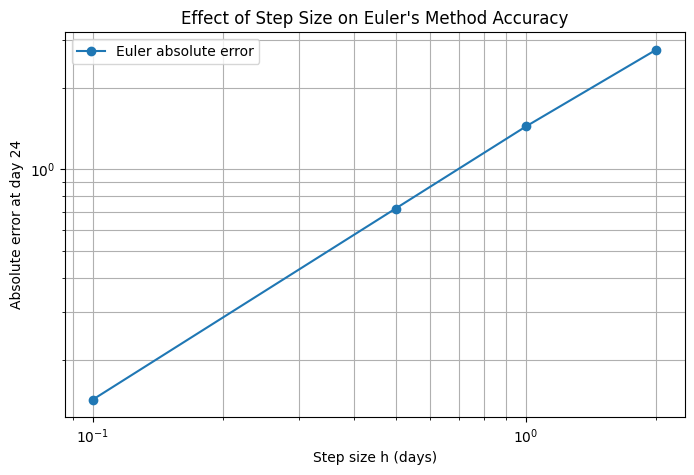

In [9]:
# Plot absolute error against step size
plt.figure(figsize=(8, 5))

plt.loglog(
    step_sizes,
    errors,
    "o-",
    label="Euler absolute error"
)

plt.xlabel("Step size h (days)")
plt.ylabel("Absolute error at day 24")
plt.title("Effect of Step Size on Euler's Method Accuracy")
plt.grid(True, which="both")
plt.legend()
plt.show()

---

# Step 9. Overall mathematical interpretation

We have now completed the bacterial growth investigation.

The workflow can be summarized as follows:

| Stage | Mathematical or computational idea | Purpose |
|---|---|---|
| 1 | Logistic differential equation | Describe population growth with limited resources |
| 2 | Analytical solution | Obtain an exact solution of the mathematical model |
| 3 | Simulated noisy observations | Represent imperfect experimental measurements |
| 4 | Nonlinear least squares | Estimate unknown parameters |
| 5 | Euler's method | Approximate the ODE numerically |
| 6 | Data visualization | Compare observations, fitted model and numerical solutions |
| 7 | Analytical prediction | Estimate the time to reach 90% of carrying capacity |
| 8 | Absolute error | Evaluate the accuracy of Euler's method |

## Connection to modern scientific computing

This small example introduces ideas used in contemporary scientific research.

**1. Data-driven modelling**

We used observations to estimate unknown model parameters.

**2. Inverse problems**

We started with data and recovered the parameters that could have generated the observations.

**3. Numerical simulation**

We used Euler's method to approximate the solution of a differential equation.

**4. Model validation**

We compared the numerical approximation with an analytical solution.

**5. Predictive modelling**

We used the fitted model to predict future population behaviour.

These ideas are building blocks for more advanced approaches such as scientific machine learning, physics-informed neural networks and neural ordinary differential equations.

> The important message is that modern scientific computing does not replace differential equations. It extends the ways in which we formulate, solve, estimate and investigate mathematical models.

---

# Step 10. Exercises for students

Try answering these questions after completing the notebook.

### Exercise 1: Effect of the growth rate

Keep $K=800$ and $P_0=40$, but change the growth rate to:

$$
r=0.20,\quad 0.35,\quad 0.50.
$$

**Questions:**

1. How does the growth rate affect the shape of the population curve?
2. Which value of $r$ produces the fastest growth?
3. Does changing $r$ change the carrying capacity?

### Exercise 2: Effect of the carrying capacity

Keep $r=0.35$ and $P_0=40$, but test:

$$
K=500,\quad 800,\quad 1200.
$$

**Questions:**

1. What happens to the final population level?
2. Does the population approach a different equilibrium?
3. How does the carrying capacity affect the population-growth curve?

### Exercise 3: Numerical accuracy

Run Euler's method using:

$$
h=2,\quad 1,\quad 0.5,\quad 0.25,\quad 0.1.
$$

**Questions:**

1. Which step size gives the smallest error?
2. Why does a smaller step size usually improve accuracy?
3. What is the disadvantage of using an extremely small step size?

### Exercise 4: Parameter estimation

Change the random seed from 12 to 25 and repeat the parameter estimation.

**Questions:**

1. Do you obtain exactly the same estimates?
2. Why do the estimates change?
3. What does this tell you about the effect of measurement noise?

### Exercise 5: Scientific interpretation

Suppose the fitted model predicts a carrying capacity of 800 bacteria, but the actual laboratory population stops growing at 600.

**Questions:**

1. What assumptions of the mathematical model might be incorrect?
2. What additional experimental information would you collect?
3. How could you improve the model?

---

## Final takeaway

The bacterial growth problem demonstrates the complete journey from a real-world question to a mathematical model, from the mathematical model to a numerical solution, and from observed data to parameter estimation and prediction.

It is a practical introduction to how differential equations and scientific computing are used together in mathematics, biology, engineering and modern scientific research.

---

# Extension: Learning Bacterial Growth with Neural Ordinary Differential Equations (Neural ODEs)

## From a known differential equation to a learned differential equation

In the previous sections, we assumed that the bacterial population followed the logistic differential equation:

$$
\frac{dP}{dt}=rP\left(1-\frac{P}{K}\right).
$$

We knew the mathematical form of the model, but we estimated its unknown parameters $r$ and $K$ from simulated observations.

Now we ask a different question:

> What if we do not know the correct formula for the rate of population growth?

This is where **Neural Ordinary Differential Equations (Neural ODEs)** become useful.

A Neural ODE uses a neural network to represent the right-hand side of a differential equation. Instead of specifying a formula such as the logistic growth law, we let the network learn a function that describes how the population changes.

The general form is

$$
\boxed{\frac{dP}{dt}=f_\theta(t,P)}
$$

where:

- $P(t)$ is the population state;
- $t$ is time;
- $f_\theta$ is a neural network;
- $\theta$ represents all trainable weights and biases of the network.

The neural network does **not** directly predict the population at a future time. It predicts the population's instantaneous rate of change. A numerical ODE solver then integrates that rate to produce the population trajectory.

## Learning objectives

By the end of this extension, you should be able to:

1. Explain the difference between a classical ODE model and a Neural ODE.
2. Understand how a neural network can represent an unknown differential-equation right-hand side.
3. Normalize time and population data for neural-network training.
4. Implement a simple differentiable Euler solver using PyTorch.
5. Train a Neural ODE using noisy bacterial-population observations.
6. Compare the learned Neural ODE with the fitted logistic model.
7. Explain why a good fit to observed data does not guarantee reliable extrapolation.

## 11.1 Classical logistic ODE versus Neural ODE

The classical logistic model assumes that the rate of change is known to have the form

$$
\frac{dP}{dt}=rP\left(1-\frac{P}{K}\right).
$$

The model has two interpretable parameters:

- $r$: intrinsic growth rate;
- $K$: carrying capacity.

A Neural ODE replaces the prescribed formula with a learnable function:

$$
\frac{dP}{dt}=f_\theta(t,P).
$$

The neural network learns the relationship between the current population and its rate of change from the observed data.

| Classical logistic ODE | Neural ODE |
|---|---|
| The right-hand-side formula is specified by the modeller. | The right-hand side is represented by a neural network. |
| Estimates parameters such as $r$ and $K$. | Learns many network weights and biases, collectively denoted by $\theta$. |
| Has a clear biological interpretation. | Is more flexible but usually less interpretable. |
| Its carrying capacity is explicit. | A carrying capacity is not automatically guaranteed. |

### Important idea

A standard neural-network regression model might learn a direct mapping from time to population:

$$
P(t)\approx g_\theta(t).
$$

A Neural ODE learns a rate function instead:

$$
\frac{dP}{dt}=f_\theta(t,P).
$$

The population curve is then generated by solving this differential equation. This continuous-time formulation is the central idea behind Neural ODEs.

## 11.2 Prepare the data and install PyTorch

We will use the same simulated bacterial observations from the previous sections:

- Initial population: $P_0=40$;
- Observation times: $t=0,2,4,\ldots,18$ days;
- Observations: `P_data`, including the simulated measurement noise.

The Neural ODE will be trained using the observations. It will **not** be given the true values of $r$ or $K$.

We use **PyTorch** because it provides:

- Neural-network layers;
- automatic differentiation;
- optimization algorithms such as Adam;
- tensor operations that can be differentiated.

If PyTorch is already installed, this installation cell may be skipped.

In [10]:
%pip install torch

### Import PyTorch

The next cell imports PyTorch and its neural-network and optimization modules.

We also set a random seed so that the initial neural-network weights are reproducible.

In [11]:
import torch
import torch.nn as nn
import torch.optim as optim

# Set the random seed for reproducible initialization
torch.manual_seed(7)

# Use single-precision floating-point numbers
torch.set_default_dtype(torch.float32)

print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.1+cpu


## 11.3 Normalize time and population

Neural networks are often easier to train when their inputs and outputs have moderate numerical scales.

Our population is measured in tens or hundreds of bacteria, while time is measured in days. We therefore introduce dimensionless variables:

$$
x=\frac{P}{S},
\qquad
\tau=\frac{t}{T_s},
$$

where:

- $S=1000$ is a reference population scale;
- $T_s=10$ days is a reference time scale;
- $x$ is the normalized population;
- $\tau$ is the normalized time.

For example, an initial population of 40 becomes

$$
x(0)=\frac{40}{1000}=0.04.
$$

The observed population values are divided by 1000, and the observation times are divided by 10.

### How does the differential equation change?

Since

$$
x=\frac{P}{S}
\quad\text{and}\quad
\tau=\frac{t}{T_s},
$$

the chain rule gives

$$
\frac{dx}{d\tau}
=
\frac{T_s}{S}\frac{dP}{dt}.
$$

We will ask the neural network to learn the normalized rate $dx/d\tau$.

The scale values are used for numerical conditioning. They are not estimates of the growth rate or carrying capacity.

In [12]:
# Reference scales for numerical normalization
POPULATION_SCALE = 1000.0
TIME_SCALE = 10.0

# Convert the existing observations to normalized variables
tau_data = torch.tensor(
    (t_data / TIME_SCALE).reshape(-1, 1),
    dtype=torch.float32
)

x_data = torch.tensor(
    (P_data / POPULATION_SCALE).reshape(-1, 1),
    dtype=torch.float32
)

# Initial normalized population
x0_tensor = torch.tensor(
    [[P0 / POPULATION_SCALE]],
    dtype=torch.float32
)

print("Normalized initial population:", x0_tensor.item())
print("Normalized observation times:")
print(tau_data.flatten())
print("Normalized observations:")
print(x_data.flatten())

Normalized initial population: 0.03999999910593033
Normalized observation times:
tensor([0.0000, 0.2000, 0.4000, 0.6000, 0.8000, 1.0000, 1.2000, 1.4000, 1.6000,
        1.8000])
Normalized observations:
tensor([0.0400, 0.0871, 0.1481, 0.2477, 0.3874, 0.4963, 0.6163, 0.6876, 0.7464,
        0.7830])


## 11.4 Define the neural network as the differential-equation model

For this introductory example, we assume that the population growth rate depends on the current population but not explicitly on time. This is called an **autonomous ODE**.

Our Neural ODE is

$$
\boxed{\frac{dx}{d\tau}=f_\theta(x).}
$$

The function $f_\theta$ is represented by a feedforward neural network.

We use the following architecture:

1. Input layer: one input, the current normalized population $x$.
2. Hidden layer 1: 24 neurons with the hyperbolic tangent activation function.
3. Hidden layer 2: 24 neurons with the hyperbolic tangent activation function.
4. Output layer: one output, the predicted derivative $dx/d\tau$.

The `Tanh` activation is a smooth nonlinear function:

$$
\tanh(z)=\frac{e^z-e^{-z}}{e^z+e^{-z}}.
$$

The network's weights and biases are the trainable parameters collected in $\theta$.

### Why does the network output a derivative?

At a particular population state $x$, the network returns a value representing the instantaneous rate of change.

For example, if the network returns

$$
f_\theta(x)=0.02,
$$

then the normalized population is increasing at approximately 0.02 normalized population units per normalized time unit at that state.

In [13]:
class NeuralVectorField(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(1, 24),
            nn.Tanh(),
            nn.Linear(24, 24),
            nn.Tanh(),
            nn.Linear(24, 1)
        )

    def forward(self, x):
        # Return the learned derivative dx/dtau
        return self.network(x)


# Create the Neural ODE vector field
neural_model = NeuralVectorField()

print(neural_model)

NeuralVectorField(
  (network): Sequential(
    (0): Linear(in_features=1, out_features=24, bias=True)
    (1): Tanh()
    (2): Linear(in_features=24, out_features=24, bias=True)
    (3): Tanh()
    (4): Linear(in_features=24, out_features=1, bias=True)
  )
)


## 11.5 Solve the Neural ODE using a differentiable Euler method

The neural network defines the derivative, but we still need a numerical method to obtain the population trajectory.

For the Neural ODE

$$
\frac{dx}{d\tau}=f_\theta(x),
$$

Euler's method gives

$$
\boxed{x_{n+1}=x_n+\Delta\tau f_\theta(x_n).}
$$

Here, $\Delta\tau$ is the normalized time step.

This is the same Euler principle used earlier for the logistic equation. The difference is that the derivative is now calculated by a neural network rather than by a prescribed logistic formula.

### Why is the solver differentiable?

PyTorch tracks the calculations made by the neural network and the Euler updates. It can therefore calculate how the final predicted populations change when the network weights change.

This allows us to train the Neural ODE using gradient-based optimization.

The following function:

1. Starts from the initial normalized population.
2. Evaluates the neural network to obtain the current derivative.
3. Applies one Euler update.
4. Repeats the process until the final time.
5. Stores the full numerical trajectory.

This is an educational fixed-step implementation. More advanced Neural ODE implementations may use adaptive numerical solvers and adjoint sensitivity methods.

In [14]:
def neural_ode_euler(model, x0, tau_end, dt):

    # Calculate the number of numerical integration steps
    number_of_steps = int(round(tau_end / dt))

    # Start from the initial state
    x = x0

    # Store the initial state
    states = [x]

    # Integrate the Neural ODE using Euler's method
    for n in range(number_of_steps):

        # Neural network estimates the derivative dx/dtau
        dx_dtau = model(x)

        # Euler update: next state = current state + step * derivative
        x = x + dt * dx_dtau

        # Store the new state
        states.append(x)

    # Create the corresponding normalized time grid
    tau_grid = torch.linspace(
        0,
        tau_end,
        number_of_steps + 1
    )

    # Combine all stored states into one tensor
    state_path = torch.cat(states, dim=0)

    return tau_grid, state_path

### Check the numerical solver before training

We can run the untrained Neural ODE once to see that it produces a trajectory.

At this stage, the network weights are random. Therefore, the resulting curve is not expected to describe bacterial growth accurately.

This is simply a test that the neural vector field and numerical integration function work together.

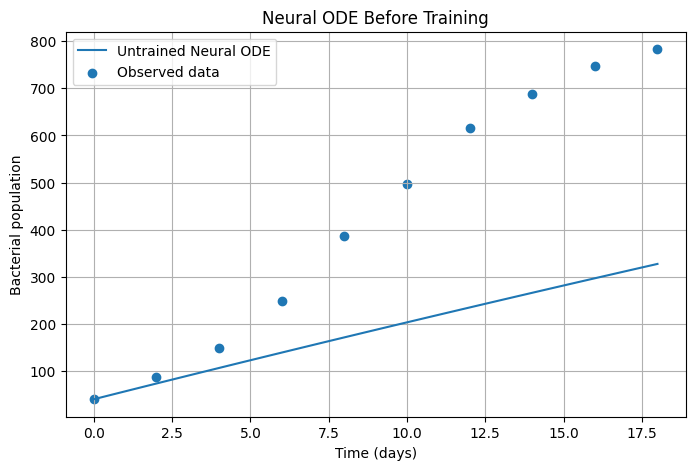

In [15]:
# Integrate the untrained Neural ODE from day 0 to day 18
tau_test, x_test = neural_ode_euler(
    neural_model,
    x0_tensor,
    tau_end=1.8,
    dt=0.02
)

# Convert normalized time and population back to their original units
t_test = tau_test.detach().numpy() * TIME_SCALE
P_test = x_test.detach().numpy().flatten() * POPULATION_SCALE

plt.figure(figsize=(8, 5))
plt.plot(t_test, P_test, label="Untrained Neural ODE")
plt.scatter(t_data, P_data, label="Observed data")
plt.xlabel("Time (days)")
plt.ylabel("Bacterial population")
plt.title("Neural ODE Before Training")
plt.legend()
plt.grid()
plt.show()

## 11.6 Train the Neural ODE using the observed bacterial data

We now adjust the neural-network parameters so that the Neural ODE trajectory follows the observed data.

### 11.6.1 Define the loss function

Let $x_i$ be the normalized observed population at time $\tau_i$.

Let $\widehat{x}_\theta(\tau_i)$ be the Neural ODE prediction at the same time.

We use the mean squared error (MSE):

$$
\boxed{
\mathcal{L}(\theta)
=
\frac{1}{N}
\sum_{i=1}^{N}
\left[
\widehat{x}_\theta(\tau_i)-x_i
\right]^2
}
$$

The objective is to find network parameters $\theta$ that minimize this loss.

A smaller loss means that the predicted trajectory is closer to the observed data on average.

### 11.6.2 Gradient-based optimization

We use the Adam optimization algorithm to update the network parameters.

The general idea of a gradient-based update is

$$
\theta_{k+1}
=
\theta_k-\eta\nabla_\theta\mathcal{L}(\theta_k),
$$

where:

- $\theta_k$ represents the network parameters at training iteration $k$;
- $\eta$ is the learning rate;
- $\nabla_\theta\mathcal{L}$ is the gradient of the loss with respect to the parameters.

PyTorch calculates these gradients using automatic differentiation.

### 11.6.3 Match the numerical time points to the observations

Our observations are separated by 2 days. Since $T_s=10$ days, the normalized observation interval is

$$
\Delta\tau_{\text{observation}}=\frac{2}{10}=0.2.
$$

We choose a numerical step size of

$$
\Delta\tau=0.02.
$$

Therefore, there are 10 Euler steps between successive observations. We select every tenth numerical state when calculating the training loss.

In [16]:
# Training settings
learning_rate = 0.005
number_of_epochs = 1200
dt_train = 0.02

# There are 10 Euler steps between observations
observation_interval = float(
    (tau_data[1] - tau_data[0]).item()
)

steps_per_observation = int(
    round(observation_interval / dt_train)
)

# Adam optimizer adjusts the neural-network parameters
optimizer = optim.Adam(
    neural_model.parameters(),
    lr=learning_rate
)

loss_history = []

# Final observation time in normalized units
tau_end_train = float(tau_data[-1].item())

for epoch in range(number_of_epochs + 1):

    # Clear gradients from the previous iteration
    optimizer.zero_grad()

    # Solve the Neural ODE over the training time interval
    tau_path, x_path = neural_ode_euler(
        neural_model,
        x0_tensor,
        tau_end=tau_end_train,
        dt=dt_train
    )

    # Select predictions at the observation times
    x_predictions = x_path[::steps_per_observation]

    # Calculate mean squared error
    loss = torch.mean((x_predictions - x_data) ** 2)

    # Calculate gradients of the loss
    loss.backward()

    # Limit unusually large gradients for more stable training
    torch.nn.utils.clip_grad_norm_(
        neural_model.parameters(),
        max_norm=1.0
    )

    # Update the neural-network parameters
    optimizer.step()

    # Save the loss for later visualization
    loss_history.append(loss.item())

    if epoch % 300 == 0:
        print(
            f"Epoch {epoch:4d} | "
            f"Training loss = {loss.item():.8f}"
        )

Epoch    0 | Training loss = 0.08796691
Epoch  300 | Training loss = 0.00146548
Epoch  600 | Training loss = 0.00135903
Epoch  900 | Training loss = 0.00004392
Epoch 1200 | Training loss = 0.00002499


### What happens during training?

At the beginning, the network has randomly initialized weights. Its predicted population curve may be far from the observations.

During each training iteration:

1. The neural network calculates the derivative.
2. Euler's method integrates the derivative to obtain a population trajectory.
3. The predicted populations are compared with the observations.
4. The loss function measures the mismatch.
5. Automatic differentiation calculates gradients with respect to the network weights.
6. Adam updates the weights to reduce the loss.

The process repeats for 1200 training iterations.

Notice that the neural network is learning a differential-equation model. It is not simply memorizing a list of population values at the observed times.

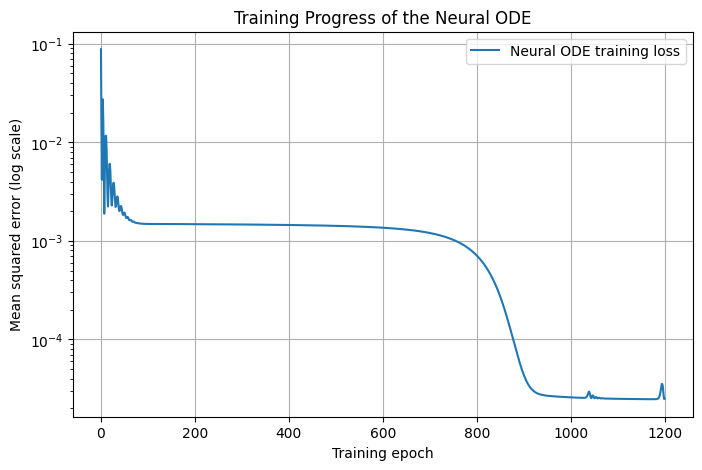

In [17]:
# Plot the training loss
plt.figure(figsize=(8, 5))

plt.semilogy(
    loss_history,
    label="Neural ODE training loss"
)

plt.xlabel("Training epoch")
plt.ylabel("Mean squared error (log scale)")
plt.title("Training Progress of the Neural ODE")
plt.legend()
plt.grid()
plt.show()

## 11.7 Evaluate the trained Neural ODE

After training, we calculate the Neural ODE trajectory again and compare it with the observed data.

We also calculate the training root mean squared error (RMSE):

$$
\mathrm{RMSE}
=
\sqrt{
\frac{1}{N}
\sum_{i=1}^{N}
\left[
\widehat{P}_i-P_i
\right]^2
}.
$$

Unlike the normalized training loss, this RMSE is expressed in the original population units (bacteria).

We compare the Neural ODE RMSE with the RMSE of the fitted logistic model.

Remember that a lower training error does not automatically mean that a model is more scientifically reliable. A flexible neural network may fit noisy observations very closely while still having poor predictive behaviour outside the observed time interval.

In [18]:
# Recalculate the trained Neural ODE trajectory
with torch.no_grad():

    tau_train_path, x_train_path = neural_ode_euler(
        neural_model,
        x0_tensor,
        tau_end=tau_end_train,
        dt=dt_train
    )

    x_train_predictions = x_train_path[::steps_per_observation]

# Convert Neural ODE predictions back to population units
P_neural_train = (
    x_train_predictions.numpy().flatten()
    * POPULATION_SCALE
)

# Calculate Neural ODE training RMSE
neural_rmse = np.sqrt(
    np.mean((P_neural_train - P_data) ** 2)
)

# Calculate logistic-model training RMSE
P_logistic_train = logistic(t_data, r_est, K_est)

logistic_rmse = np.sqrt(
    np.mean((P_logistic_train - P_data) ** 2)
)

print("Neural ODE training RMSE:", round(neural_rmse, 3))
print("Logistic model training RMSE:", round(logistic_rmse, 3))

Neural ODE training RMSE: 5.161
Logistic model training RMSE: 9.615


## 11.8 Compare the Neural ODE with the classical logistic model

We now plot:

- The noisy simulated observations;
- The fitted classical logistic model;
- The trained Neural ODE trajectory.

Both models are fitted or trained using the same observations.

The logistic model has an explicit mathematical form and interpretable parameters. The Neural ODE learns a flexible rate function from the observations.

This comparison illustrates two different ways of modelling the same biological system.

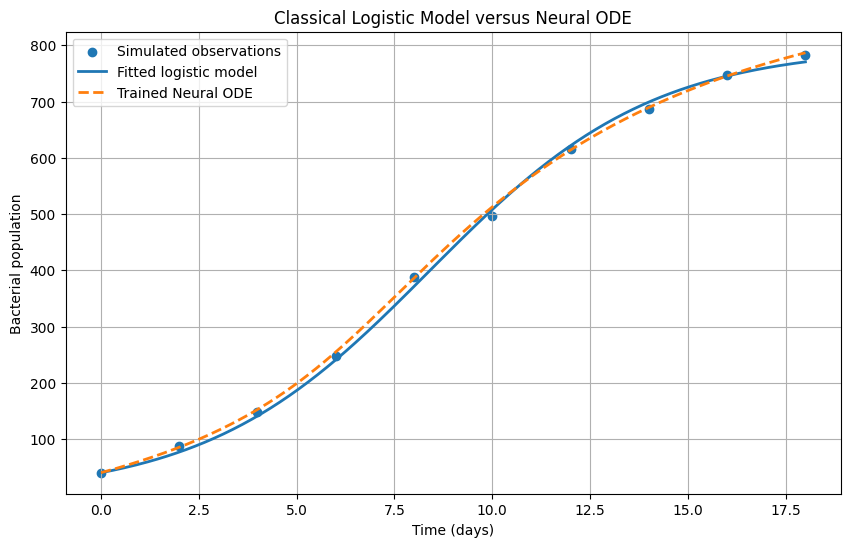

In [19]:
# Generate a smooth Neural ODE trajectory over the observed interval
with torch.no_grad():

    tau_neural_train, x_neural_train = neural_ode_euler(
        neural_model,
        x0_tensor,
        tau_end=1.8,
        dt=0.01
    )

t_neural_train = (
    tau_neural_train.numpy() * TIME_SCALE
)

P_neural_train_curve = (
    x_neural_train.numpy().flatten()
    * POPULATION_SCALE
)

# Smooth time values for the logistic model
t_smooth = np.linspace(0, 18, 300)

plt.figure(figsize=(10, 6))

plt.scatter(
    t_data,
    P_data,
    label="Simulated observations"
)

plt.plot(
    t_smooth,
    logistic(t_smooth, r_est, K_est),
    linewidth=2,
    label="Fitted logistic model"
)

plt.plot(
    t_neural_train,
    P_neural_train_curve,
    linewidth=2,
    linestyle="--",
    label="Trained Neural ODE"
)

plt.xlabel("Time (days)")
plt.ylabel("Bacterial population")
plt.title("Classical Logistic Model versus Neural ODE")
plt.legend()
plt.grid()
plt.show()

## 11.9 Predict beyond the observed data: extrapolation

So far, the Neural ODE has only been trained using observations from day 0 to day 18.

What happens if we ask both models to predict the population at day 24?

This is called **extrapolation**: making predictions outside the time interval covered by the training observations.

We integrate the trained Neural ODE to 24 days and compare its prediction with the fitted logistic model.

### Why is extrapolation important?

A Neural ODE may fit the observed data well but still learn a rate function that behaves differently outside the observed population range.

The logistic model explicitly contains the carrying capacity $K$. In contrast, our Neural ODE has not been told that the population must approach a particular maximum.

Therefore, it is not guaranteed to:

- remain below a carrying capacity;
- approach a stable equilibrium;
- remain nonnegative for every possible initial condition;
- predict accurately beyond the observed data.

This is an important scientific lesson: **a good fit to known observations does not guarantee reliable future predictions.**

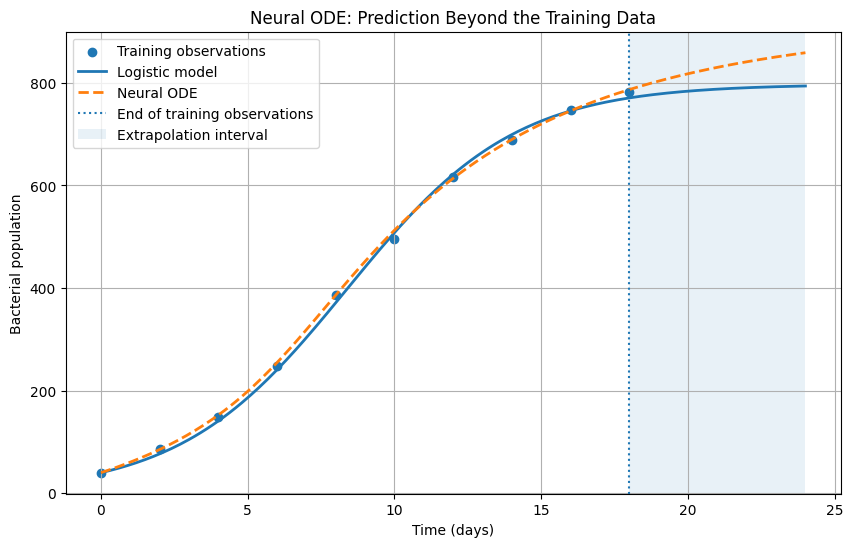

Neural ODE prediction at day 24: 858.7
Logistic model prediction at day 24: 793.84


In [20]:
# Integrate the trained Neural ODE up to 24 days
with torch.no_grad():

    tau_extended, x_extended = neural_ode_euler(
        neural_model,
        x0_tensor,
        tau_end=24 / TIME_SCALE,
        dt=0.01
    )

# Convert back to days and population units
t_extended = tau_extended.numpy() * TIME_SCALE

P_neural_extended = (
    x_extended.numpy().flatten()
    * POPULATION_SCALE
)

# Classical logistic model prediction
P_logistic_extended = logistic(
    t_extended,
    r_est,
    K_est
)

plt.figure(figsize=(10, 6))

plt.scatter(
    t_data,
    P_data,
    label="Training observations"
)

plt.plot(
    t_extended,
    P_logistic_extended,
    linewidth=2,
    label="Logistic model"
)

plt.plot(
    t_extended,
    P_neural_extended,
    linewidth=2,
    linestyle="--",
    label="Neural ODE"
)

# Mark the end of the observed data
plt.axvline(
    18,
    linestyle=":",
    label="End of training observations"
)

plt.axvspan(
    18,
    24,
    alpha=0.10,
    label="Extrapolation interval"
)

plt.xlabel("Time (days)")
plt.ylabel("Bacterial population")
plt.title("Neural ODE: Prediction Beyond the Training Data")
plt.legend()
plt.grid()
plt.show()

print(
    "Neural ODE prediction at day 24:",
    round(float(P_neural_extended[-1]), 2)
)

print(
    "Logistic model prediction at day 24:",
    round(float(P_logistic_extended[-1]), 2)
)

### Interpret the extrapolation graph

Look carefully at the two curves after day 18.

The logistic model approaches its estimated carrying capacity because this behaviour is built into its equation.

The Neural ODE may continue increasing, approach a different level, or display another behaviour depending on the learned vector field.

This does not mean that Neural ODEs are inherently poor models. It means that their flexibility must be supported by sufficient data, appropriate assumptions, physical constraints or additional regularization.

For bacterial growth, biological knowledge tells us that resources are limited. A model that does not incorporate or learn this behaviour reliably may make unrealistic long-term predictions.

## 11.10 What differential equation has the Neural ODE learned?

The neural network represents a vector field: a function that assigns a rate of change to each population state.

Our model learns

$$
\frac{dx}{d\tau}=f_\theta(x).
$$

To compare this with the classical model, we convert the learned normalized derivative back into the original units.

Recall that

$$
\frac{dx}{d\tau}
=
\frac{T_s}{S}\frac{dP}{dt}.
$$

Therefore,

$$
\boxed{
\frac{dP}{dt}
=
\frac{S}{T_s}f_\theta\left(\frac{P}{S}\right).
}
$$

For the fitted logistic model, the corresponding rate is

$$
\frac{dP}{dt}
=
r_{\mathrm{est}}P
\left(1-\frac{P}{K_{\mathrm{est}}}\right).
$$

We can plot both rates against population to see how the neural network has learned the relationship between population and growth rate.

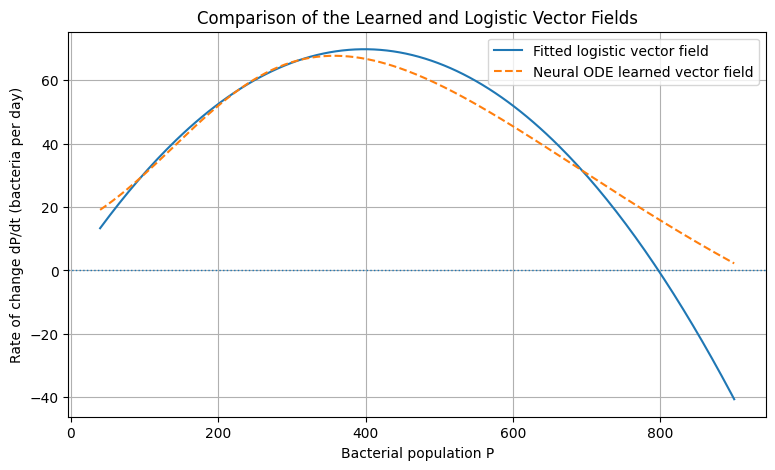

In [21]:
# Population values at which we evaluate the learned vector field
P_grid = np.linspace(40, 900, 200)

# Convert population to normalized state
x_grid = torch.tensor(
    (P_grid / POPULATION_SCALE).reshape(-1, 1),
    dtype=torch.float32
)

# Evaluate the neural network's learned derivative
with torch.no_grad():
    dx_dtau_neural = neural_model(x_grid).numpy().flatten()

# Convert the normalized derivative to bacteria per day
dP_dt_neural = (
    POPULATION_SCALE / TIME_SCALE
) * dx_dtau_neural

# Evaluate the fitted logistic model's derivative
dP_dt_logistic = (
    r_est * P_grid * (1 - P_grid / K_est)
)

plt.figure(figsize=(9, 5))

plt.plot(
    P_grid,
    dP_dt_logistic,
    label="Fitted logistic vector field"
)

plt.plot(
    P_grid,
    dP_dt_neural,
    linestyle="--",
    label="Neural ODE learned vector field"
)

plt.axhline(0, linestyle=":", linewidth=1)

plt.xlabel("Bacterial population P")
plt.ylabel("Rate of change dP/dt (bacteria per day)")
plt.title("Comparison of the Learned and Logistic Vector Fields")
plt.legend()
plt.grid()
plt.show()

### How to interpret the vector-field graph

The horizontal axis represents the current population $P$.

The vertical axis represents the rate of population change $dP/dt$.

For the logistic model:

- The rate is positive when $0<P<K$.
- The rate is zero at $P=K$.
- The rate becomes negative when $P>K$ in the mathematical model.

For the Neural ODE:

- The network has learned a rate function from the observed trajectory.
- It may approximate the logistic rate over the range supported by the observations.
- Outside that range, its predictions are not strongly constrained by the data.

The graph helps us understand that a Neural ODE learns a differential-equation vector field, not merely a smooth curve through the data points.

## 11.11 Limitations and possible improvements

This is a deliberately small teaching example. It demonstrates the main Neural ODE idea, but it is not a complete research-grade model.

### Limitation 1: Only one observed trajectory

We trained the network using one bacterial population trajectory. A single trajectory may not provide enough information to identify the underlying dynamics uniquely.

**Possible improvement:** Collect observations from several experiments with different initial populations.

### Limitation 2: No explicit carrying-capacity constraint

The neural network is free to learn a rate function. It is not automatically forced to approach a stable carrying capacity.

**Possible improvement:** Incorporate biological constraints or use a hybrid model that combines a known logistic structure with a learned correction.

### Limitation 3: Numerical integration error

We used a fixed-step Euler solver. Its accuracy depends on the step size.

**Possible improvement:** Compare Euler's method with Runge-Kutta methods or adaptive ODE solvers.

### Limitation 4: Measurement noise

The observed population values contain random noise. The neural network may learn some of this noise rather than only the underlying biological dynamics.

**Possible improvement:** Use regularization, more observations, validation data and uncertainty analysis.

### Limitation 5: Extrapolation

The neural network is trained only up to day 18. Predictions after day 18 are not directly supported by observations.

**Possible improvement:** Collect longer-term observations and evaluate predictions on data that were not used during training.

## 11.12 Classical ODE versus Neural ODE: final comparison

| Feature | Logistic ODE | Neural ODE |
|---|---|---|
| Governing equation | Prescribed logistic formula | Neural network vector field |
| Unknown quantities | Growth rate and carrying capacity | Network weights and biases |
| Solution method here | Analytical solution or Euler method | Differentiable Euler integration |
| Parameter estimation | Nonlinear least squares | Gradient-based neural-network training |
| Interpretability | High | Usually lower |
| Flexibility | Restricted to the chosen model | More flexible |
| Extrapolation | Guided by logistic assumptions | Depends strongly on learned dynamics and data |

## 11.13 Connection to modern scientific computing

Neural ODEs are one example of **scientific machine learning (SciML)**.

They connect three important ideas:

1. **Differential equations:** describe how a system evolves continuously over time.
2. **Neural networks:** learn unknown mathematical relationships from data.
3. **Numerical analysis:** provides algorithms to integrate the learned differential equation.

A simplified Neural ODE workflow is:

$$
\text{Observed data}
\longrightarrow
\text{Neural network vector field}
\longrightarrow
\text{ODE solver}
\longrightarrow
\text{Predicted trajectory}
$$

The model is trained by comparing the predicted trajectory with the observations and adjusting the network parameters.

### An important technical note

This notebook uses a fixed-step Euler solver and differentiates through its numerical updates using PyTorch automatic differentiation.

It is a beginner-friendly implementation of the Neural ODE concept. More advanced implementations may use adaptive solvers and the adjoint sensitivity method to compute gradients more efficiently.

For further reading:

Chen, R. T. Q., Rubanova, Y., Bettencourt, J., & Duvenaud, D. (2018). Neural Ordinary Differential Equations. *Advances in Neural Information Processing Systems, 31*.

https://arxiv.org/abs/1806.07366

---

# Student activities: Neural ODE extension

Complete these activities after running the Neural ODE cells.

### Activity 1: Change the neural-network size

Change the hidden layers from 24 neurons to 8 neurons, then to 48 neurons.

**Questions:**

1. How does the training loss change?
2. Does a larger network always produce a more reliable model?
3. What happens to the extrapolated prediction?

### Activity 2: Change the learning rate

Try the following learning rates:

$$
\eta=0.001,\quad 0.005,\quad 0.02.
$$

**Questions:**

1. Which learning rate gives the smoothest training process?
2. What happens when the learning rate is too large?
3. Why is the learning rate important in gradient-based optimization?

### Activity 3: Change the numerical step size

Try:

$$
\Delta\tau=0.04,\quad 0.02,\quad 0.01.
$$

**Questions:**

1. How does the step size affect the numerical trajectory?
2. How does it affect training time?
3. Why should numerical integration accuracy be considered during Neural ODE training?

### Activity 4: Compare the models

Compare the classical logistic model and the Neural ODE.

**Questions:**

1. Which model has the smaller training RMSE?
2. Which model has the clearer biological interpretation?
3. Which model has an explicit carrying capacity?
4. Why might the Neural ODE's extrapolation be less reliable?

### Activity 5: Research discussion

Suppose a laboratory collects bacterial population data from five experiments, each with a different initial population.

**Questions:**

1. Why might multiple trajectories help train a Neural ODE?
2. How could the model be tested on an initial population it has not seen before?
3. What biological constraints could be incorporated into the model?

---

## Final takeaway

The classical logistic model starts with a known differential equation and estimates its parameters from observations.

The Neural ODE takes a different approach: it uses a neural network to learn the differential equation's rate function and a numerical solver to generate the population trajectory.

Both methods combine mathematics and computation, but they make different assumptions and offer different advantages.

The central lesson is:

> A differential equation can be used not only to describe a known mathematical model, but also as a framework for learning unknown dynamics from data.

---

# Extension 2: Physics-Informed Neural Networks (PINNs)

## Comparing a PINN, a Neural ODE and a classical numerical solver

In the previous extension, we introduced a Neural ODE. Its neural network learned the rate of population change from the observed bacterial data.

Now we introduce a different scientific machine-learning method: the **Physics-Informed Neural Network (PINN)**.

A PINN uses a neural network to approximate the solution of a differential equation. During training, it is encouraged to satisfy both:

1. The observed data;
2. The governing differential equation and its initial condition.

We will use the same bacterial-growth problem:

$$
\frac{dP}{dt}=rP\left(1-\frac{P}{K}\right),
\qquad P(0)=P_0=40.
$$

Our goal is to compare three approaches:

- **Classical numerical solution:** use a conventional ODE solver, specifically the adaptive Runge–Kutta method RK45.
- **Neural ODE:** learn the rate function from observations and integrate the learned rate.
- **PINN:** learn the population trajectory while penalizing violations of the logistic differential equation.

The same simulated observations and fitted parameters from the earlier sections will be used.

## Learning objectives

By the end of this extension, you should be able to:

1. Explain the main idea of a physics-informed neural network.
2. Construct a neural network that approximates the bacterial population as a function of time.
3. Use automatic differentiation to calculate the network's time derivative.
4. Form a physics residual from the logistic differential equation.
5. Train a PINN using data, physics and initial-condition losses.
6. Compare the PINN with a classical numerical solution and a Neural ODE.
7. Explain why these three approaches use different information and have different strengths.

## 12.1 What is a Physics-Informed Neural Network?

A conventional neural network can be trained to fit observations. For example, it may learn a function that maps time to population:

$$
P_\theta(t)\approx P(t).
$$

Here, $P_\theta(t)$ is the neural network's approximation of the bacterial population, and $\theta$ denotes its trainable weights and biases.

A PINN adds knowledge of the governing differential equation to the training process.

For our bacterial model, the differential equation is

$$
\frac{dP}{dt}=rP\left(1-\frac{P}{K}\right).
$$

If the neural network represents a valid solution, then it should satisfy

$$
\frac{dP_\theta}{dt}
-rP_\theta\left(1-\frac{P_\theta}{K}\right)
=0.
$$

We define the **physics residual** as

$$
\boxed{
\mathcal{R}_\theta(t)
=
\frac{dP_\theta}{dt}
-rP_\theta(t)\left(1-\frac{P_\theta(t)}{K}\right).
}
$$

An ideal solution has a residual of zero throughout the time domain.

A PINN therefore learns a population function that both follows the observations and approximately satisfies the differential equation.

### PINN versus Neural ODE

These methods use neural networks in different ways:

| Method | What does its neural network learn? |
|---|---|
| Neural ODE | The derivative or vector field, such as $dP/dt=f_\theta(P,t)$ |
| PINN | The solution itself, such as $P_\theta(t)$ |

The Neural ODE then integrates its learned derivative. The PINN directly approximates the population trajectory and uses the differential equation to constrain that trajectory.

## 12.2 The three components of the PINN loss function

A PINN is trained by minimizing a combination of loss terms.

### A. Data loss

At each observation time $t_i$, the neural network predicts $P_\theta(t_i)$.

The data loss is

$$
\boxed{
\mathcal{L}_{\mathrm{data}}
=
\frac{1}{N}
\sum_{i=1}^{N}
\left[P_\theta(t_i)-P_i\right]^2.
}
$$

This term encourages the network to fit the simulated experimental observations.

### B. Physics loss

At selected time points called **collocation points**, we evaluate the differential-equation residual.

The physics loss is

$$
\boxed{
\mathcal{L}_{\mathrm{physics}}
=
\frac{1}{M}
\sum_{j=1}^{M}
\left[\mathcal{R}_\theta(t_j^{c})\right]^2.
}
$$

The collocation points do not need to be experimental observations. They are points at which we enforce the mathematical law.

### C. Initial-condition loss

The initial population must satisfy

$$
P_\theta(0)=40.
$$

We penalize any difference between the network's initial prediction and the known initial population:

$$
\boxed{
\mathcal{L}_{\mathrm{IC}}
=
\left[P_\theta(0)-40\right]^2.
}
$$

### D. Total PINN loss

We combine the three terms:

$$
\boxed{
\mathcal{L}_{\mathrm{total}}
=
\lambda_d\mathcal{L}_{\mathrm{data}}
+
\lambda_p\mathcal{L}_{\mathrm{physics}}
+
\lambda_0\mathcal{L}_{\mathrm{IC}}.
}
$$

The coefficients $\lambda_d$, $\lambda_p$ and $\lambda_0$ control the relative importance of each loss component.

In this demonstration, we use:

- $\lambda_d=10$;
- $\lambda_p=1$;
- $\lambda_0=10$.

These are teaching-example settings, not universal optimal values. The appropriate weights depend on the scales of the data and residuals.

## 12.3 Normalize time and population

As in the Neural ODE section, we normalize the variables to improve numerical conditioning.

Define

$$
x=\frac{P}{S},
\qquad
\tau=\frac{t}{T_s},
$$

where $S=1000$ and $T_s=10$ days.

Using the chain rule,

$$
\frac{dx}{d\tau}
=
\frac{T_s}{S}\frac{dP}{dt}.
$$

Substitute the logistic equation:

$$
\frac{dx}{d\tau}
=
\frac{T_s}{S}
r(Sx)\left(1-\frac{Sx}{K}\right).
$$

Therefore, the normalized logistic equation is

$$
\boxed{
\frac{dx}{d\tau}
=
T_s r x\left(1-\frac{Sx}{K}\right).
}
$$

We use the fitted parameters $r_{\mathrm{est}}$ and $K_{\mathrm{est}}$ obtained in the earlier parameter-estimation section.

**Important modelling choice:** In this forward PINN demonstration, the logistic equation and its fitted parameters are treated as known physics. The PINN learns an approximate solution to that equation. It is not independently discovering the logistic equation or estimating $r$ and $K$ from scratch.

We will use collocation points from day 0 to day 24. The observed data stop at day 18, so the interval from day 18 to day 24 has physics constraints but no experimental observations. This allows us to examine how known physics can guide predictions beyond the observed data.

## 12.4 Prepare the PINN data and collocation points

The observed data are already available from the earlier sections as `t_data` and `P_data`.

We convert them to normalized variables:

$$
\tau_i=\frac{t_i}{T_s},
\qquad
x_i=\frac{P_i}{S}.
$$

We also create 241 equally spaced collocation points from $\tau=0$ to $\tau=2.4$. Since $T_s=10$, this corresponds to 0 through 24 days.

The collocation points are where the PINN is asked to satisfy the differential equation.

In [22]:
import torch
import torch.nn as nn
import torch.optim as optim
from scipy.integrate import solve_ivp

# Normalization constants
PINN_POPULATION_SCALE = 1000.0
PINN_TIME_SCALE = 10.0

# Reproducible PINN initialization
torch.manual_seed(21)

# Normalized observed data
tau_obs_pinn = torch.tensor(
    (t_data / PINN_TIME_SCALE).reshape(-1, 1),
    dtype=torch.float32
)

x_obs_pinn = torch.tensor(
    (P_data / PINN_POPULATION_SCALE).reshape(-1, 1),
    dtype=torch.float32
)

# Normalized initial condition
x0_pinn = torch.tensor(
    [[P0 / PINN_POPULATION_SCALE]],
    dtype=torch.float32
)

# Collocation domain: normalized time 0 to 2.4, or 0 to 24 days
tau_collocation = torch.linspace(
    0.0, 2.4, 241
).reshape(-1, 1)

# The input must require gradients so that autograd can calculate dx/dtau
tau_collocation.requires_grad_(True)

print("Number of observed data points:", len(tau_obs_pinn))
print("Number of collocation points:", len(tau_collocation))
print("Estimated r:", r_est)
print("Estimated K:", K_est)

Number of observed data points: 10
Number of collocation points: 241
Estimated r: 0.35040260160040987
Estimated K: 797.1892433171164


## 12.5 Define the PINN neural network

The PINN network takes normalized time $\tau$ as its input and predicts normalized population $x_\theta(\tau)$.

We use a simple feedforward network:

- Input: one variable, normalized time $\tau$;
- Hidden layer 1: 32 neurons with `Tanh` activation;
- Hidden layer 2: 32 neurons with `Tanh` activation;
- Output: one variable, predicted normalized population.

Mathematically, the network represents

$$
x_\theta(\tau)=\operatorname{NN}_\theta(\tau).
$$

We use a smooth `Tanh` activation because the PINN needs a differentiable output to calculate the time derivative.

In [23]:
class BacteriaPINN(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(1, 32),
            nn.Tanh(),
            nn.Linear(32, 32),
            nn.Tanh(),
            nn.Linear(32, 1)
        )

    def forward(self, tau):
        # Predict normalized bacterial population
        return self.network(tau)


# Create the PINN model
pinn_model = BacteriaPINN()

print(pinn_model)

BacteriaPINN(
  (network): Sequential(
    (0): Linear(in_features=1, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): Tanh()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


## 12.6 Calculate the physics residual using automatic differentiation

This is the central step in a PINN.

The neural network predicts $x_\theta(\tau)$. We need its derivative with respect to normalized time:

$$
\frac{dx_\theta}{d\tau}.
$$

PyTorch's automatic differentiation calculates this derivative.

The normalized logistic equation is

$$
\frac{dx}{d\tau}
=
T_s r_{\mathrm{est}}x
\left(1-\frac{Sx}{K_{\mathrm{est}}}\right).
$$

Therefore, the normalized physics residual is

$$
\boxed{
\mathcal{R}_\theta(\tau)
=
\frac{dx_\theta}{d\tau}
-
T_s r_{\mathrm{est}}x_\theta
\left(1-\frac{Sx_\theta}{K_{\mathrm{est}}}\right).
}
$$

If the network satisfies the logistic differential equation perfectly, this residual is zero.

### Why do we use `create_graph=True`?

We need the derivative of the network output with respect to time. We also need to calculate how the residual changes when the network weights change.

`create_graph=True` tells PyTorch to retain the derivative calculation as part of a computational graph. This allows us to backpropagate the physics loss through the derivative and update the network weights.

In [24]:
def pinn_physics_residual(model, tau):

    # Predict normalized population at collocation points
    x = model(tau)

    # Calculate dx/dtau using automatic differentiation
    dx_dtau = torch.autograd.grad(
        outputs=x,
        inputs=tau,
        grad_outputs=torch.ones_like(x),
        create_graph=True
    )[0]

    # Right-hand side of the normalized logistic equation
    logistic_rhs = (
        PINN_TIME_SCALE
        * r_est
        * x
        * (1 - PINN_POPULATION_SCALE * x / K_est)
    )

    # Physics residual: derivative minus governing equation
    residual = dx_dtau - logistic_rhs

    return residual

## 12.7 Train the PINN

We now calculate the three loss components.

**Data loss:** compare the network predictions with the observed populations.

**Physics loss:** calculate the differential-equation residual at the collocation points.

**Initial-condition loss:** enforce the known initial population of 40 bacteria.

The total loss is

$$
\mathcal{L}_{\mathrm{total}}
=
10\mathcal{L}_{\mathrm{data}}
+
\mathcal{L}_{\mathrm{physics}}
+
10\mathcal{L}_{\mathrm{IC}}.
$$

We use the Adam optimizer to minimize this loss.

The training process follows these steps:

1. Predict the population at observed times.
2. Predict the population at collocation points.
3. Use automatic differentiation to calculate the time derivative.
4. Calculate the data, physics and initial-condition losses.
5. Combine the losses.
6. Backpropagate the total loss.
7. Update the neural-network weights.

We train for 5000 epochs in this example. Training duration and convergence depend on the machine, initialization, network architecture and loss weights.

In [25]:
# PINN training settings
PINN_LEARNING_RATE = 0.001
PINN_EPOCHS = 5000

lambda_data = 10.0
lambda_physics = 1.0
lambda_initial = 10.0

# Adam optimizer
pinn_optimizer = optim.Adam(
    pinn_model.parameters(),
    lr=PINN_LEARNING_RATE
)

# Store total and component losses
pinn_total_history = []
pinn_data_history = []
pinn_physics_history = []
pinn_initial_history = []

for epoch in range(PINN_EPOCHS + 1):

    pinn_optimizer.zero_grad()

    # 1. Data loss
    x_data_prediction = pinn_model(tau_obs_pinn)

    loss_data = torch.mean(
        (x_data_prediction - x_obs_pinn) ** 2
    )

    # 2. Physics loss
    residual = pinn_physics_residual(
        pinn_model,
        tau_collocation
    )

    loss_physics = torch.mean(residual ** 2)

    # 3. Initial-condition loss
    tau_zero = torch.zeros((1, 1), dtype=torch.float32)

    x_initial_prediction = pinn_model(tau_zero)

    loss_initial = torch.mean(
        (x_initial_prediction - x0_pinn) ** 2
    )

    # 4. Total weighted loss
    total_loss = (
        lambda_data * loss_data
        + lambda_physics * loss_physics
        + lambda_initial * loss_initial
    )

    # 5. Backpropagation
    total_loss.backward()

    # Limit unusually large gradients
    torch.nn.utils.clip_grad_norm_(
        pinn_model.parameters(),
        max_norm=1.0
    )

    # 6. Update the network parameters
    pinn_optimizer.step()

    # Save the loss values
    pinn_total_history.append(total_loss.item())
    pinn_data_history.append(loss_data.item())
    pinn_physics_history.append(loss_physics.item())
    pinn_initial_history.append(loss_initial.item())

    if epoch % 500 == 0:
        print(
            f"Epoch {epoch:4d} | "
            f"Total: {total_loss.item():.8f} | "
            f"Data: {loss_data.item():.8f} | "
            f"Physics: {loss_physics.item():.8f} | "
            f"Initial: {loss_initial.item():.8f}"
        )

Epoch    0 | Total: 18.80898666 | Data: 0.93575889 | Physics: 8.60844803 | Initial: 0.08429495
Epoch  500 | Total: 0.00078348 | Data: 0.00004664 | Physics: 0.00031267 | Initial: 0.00000044
Epoch 1000 | Total: 0.00072465 | Data: 0.00005322 | Physics: 0.00018890 | Initial: 0.00000035
Epoch 1500 | Total: 0.00071285 | Data: 0.00005433 | Physics: 0.00016593 | Initial: 0.00000036
Epoch 2000 | Total: 0.00070411 | Data: 0.00005451 | Physics: 0.00015528 | Initial: 0.00000037
Epoch 2500 | Total: 0.00069714 | Data: 0.00005472 | Physics: 0.00014684 | Initial: 0.00000031
Epoch 3000 | Total: 0.00073018 | Data: 0.00005825 | Physics: 0.00014162 | Initial: 0.00000061
Epoch 3500 | Total: 0.00068624 | Data: 0.00005445 | Physics: 0.00013781 | Initial: 0.00000039
Epoch 4000 | Total: 0.00068355 | Data: 0.00005444 | Physics: 0.00013709 | Initial: 0.00000020
Epoch 4500 | Total: 0.00068285 | Data: 0.00005366 | Physics: 0.00013694 | Initial: 0.00000093
Epoch 5000 | Total: 0.00067873 | Data: 0.00005475 | Physics

### Interpret the training losses

The total loss should generally decrease during training, although small fluctuations are normal with Adam.

Each component has a different meaning:

- A smaller data loss indicates that the PINN predictions are closer to the observations.
- A smaller physics loss indicates that the predicted trajectory more closely satisfies the logistic differential equation.
- A smaller initial-condition loss indicates that the predicted population at day zero is closer to 40.

The PINN is not simply trying to pass through every noisy observation. It balances the observed data with the mathematical law.

This is especially useful when observations are sparse or noisy, provided that the assumed governing equation is appropriate.

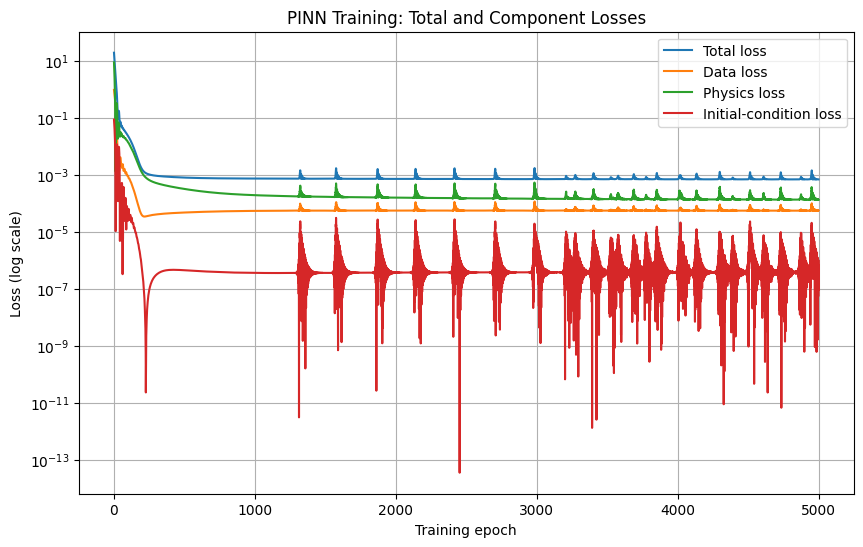

In [26]:
# Plot the three PINN loss components
plt.figure(figsize=(10, 6))

plt.semilogy(
    pinn_total_history,
    label="Total loss"
)

plt.semilogy(
    pinn_data_history,
    label="Data loss"
)

plt.semilogy(
    pinn_physics_history,
    label="Physics loss"
)

plt.semilogy(
    pinn_initial_history,
    label="Initial-condition loss"
)

plt.xlabel("Training epoch")
plt.ylabel("Loss (log scale)")
plt.title("PINN Training: Total and Component Losses")
plt.legend()
plt.grid()
plt.show()

## 12.8 Obtain the PINN population prediction

After training, we evaluate the network on a dense time grid.

The network predicts normalized population $x_\theta(\tau)$. We convert the result back to the original units:

$$
P_\theta(t)=Sx_\theta\left(\frac{t}{T_s}\right).
$$

This gives the PINN's predicted bacterial population in bacteria rather than normalized units.

In [27]:
# Evaluate the trained PINN from day 0 to day 24
tau_comparison = torch.linspace(
    0.0, 2.4, 241
).reshape(-1, 1)

with torch.no_grad():
    x_pinn_prediction = pinn_model(tau_comparison)

# Convert normalized time and population to original units
t_comparison = (
    tau_comparison.numpy().flatten()
    * PINN_TIME_SCALE
)

P_pinn_prediction = (
    x_pinn_prediction.numpy().flatten()
    * PINN_POPULATION_SCALE
)

print(
    "PINN prediction at day 24:",
    round(float(P_pinn_prediction[-1]), 2)
)

PINN prediction at day 24: 793.88


## 12.9 Compute a classical numerical solution using RK45

We now calculate a conventional numerical solution of the fitted logistic equation.

SciPy's `solve_ivp()` solves an initial value problem. We use its RK45 method, an adaptive Runge–Kutta method.

The equation is

$$
\frac{dP}{dt}
=
r_{\mathrm{est}}P
\left(1-\frac{P}{K_{\mathrm{est}}}\right),
\qquad P(0)=40.
$$

Unlike fixed-step Euler's method, RK45 automatically adjusts its internal step size to control local numerical error.

We request output at 241 equally spaced times between day 0 and day 24. The tolerances are set to small values so that this solution acts as a high-accuracy numerical reference for our comparison.

The RK45 solution uses the known logistic equation and the fitted parameters. It does not use a neural network.

In [28]:
# Define the fitted logistic differential equation
def fitted_logistic_rhs(t, P):
    return (
        r_est
        * P
        * (1 - P / K_est)
    )

# Requested output times: 0 to 24 days
t_eval_comparison = np.linspace(0, 24, 241)

# Solve using the adaptive Runge-Kutta RK45 method
rk45_solution = solve_ivp(
    fitted_logistic_rhs,
    t_span=(0, 24),
    y0=[P0],
    method="RK45",
    t_eval=t_eval_comparison,
    rtol=1e-10,
    atol=1e-12
)

# Extract the numerical solution
P_rk45 = rk45_solution.y[0]

print("RK45 solver successful:", rk45_solution.success)
print("RK45 prediction at day 24:", round(P_rk45[-1], 4))

RK45 solver successful: True
RK45 prediction at day 24: 793.8426


### Verify the RK45 solution against the analytical solution

For this particular problem, we know the analytical logistic solution. We can use it to check the numerical solver.

The maximum absolute difference over the requested time grid is

$$
E_{\max}
=
\max_i
\left|
P_{\mathrm{RK45}}(t_i)-P_{\mathrm{analytical}}(t_i)
\right|.
$$

A small value indicates that the RK45 solution closely matches the analytical solution.

In [29]:
# Evaluate the analytical fitted logistic solution on the same grid
P_analytical_comparison = logistic(
    t_eval_comparison,
    r_est,
    K_est
)

# Maximum absolute difference between RK45 and analytical solution
rk45_max_error = np.max(
    np.abs(P_rk45 - P_analytical_comparison)
)

print(
    "Maximum RK45 versus analytical difference:",
    f"{rk45_max_error:.10f}"
)

Maximum RK45 versus analytical difference: 0.0000007052


## 12.10 Obtain the Neural ODE prediction on the same time grid

The Neural ODE was trained in the previous extension using the observed bacterial data.

Its neural network learns a vector field:

$$
\frac{dx}{d\tau}=f_\theta(x).
$$

We integrate that learned vector field up to day 24 using the differentiable Euler solver already defined in the Neural ODE section.

This is different from the PINN:

- The Neural ODE learns the derivative from the observed trajectory.
- The PINN learns the population function while being constrained by the known logistic equation.

The Neural ODE is not given the logistic equation during its data-fitting process.

In [30]:
# Integrate the trained Neural ODE from day 0 to day 24
with torch.no_grad():

    tau_neural_comparison, x_neural_comparison = neural_ode_euler(
        neural_model,
        x0_tensor,
        tau_end=2.4,
        dt=0.01
    )

# Convert the Neural ODE output to original units
t_neural_comparison = (
    tau_neural_comparison.numpy() * PINN_TIME_SCALE
)

P_neural_comparison = (
    x_neural_comparison.numpy().flatten()
    * PINN_POPULATION_SCALE
)

print(
    "Neural ODE prediction at day 24:",
    round(float(P_neural_comparison[-1]), 2)
)

Neural ODE prediction at day 24: 858.7


## 12.11 Compare the three approaches graphically

We now plot the same bacterial-growth problem using:

1. RK45 numerical solution;
2. Neural ODE;
3. PINN;
4. Simulated experimental observations.

All curves are shown in the original units of days and bacterial population.

The observation data end at day 18. The interval from day 18 to day 24 is the extrapolation interval.

The PINN uses the logistic equation as a physics constraint throughout the full interval from day 0 to day 24. The Neural ODE is trained from the observed trajectory only, up to day 18. The RK45 solver uses the fitted logistic equation throughout the full interval.

This difference in available information is important when interpreting the comparison.

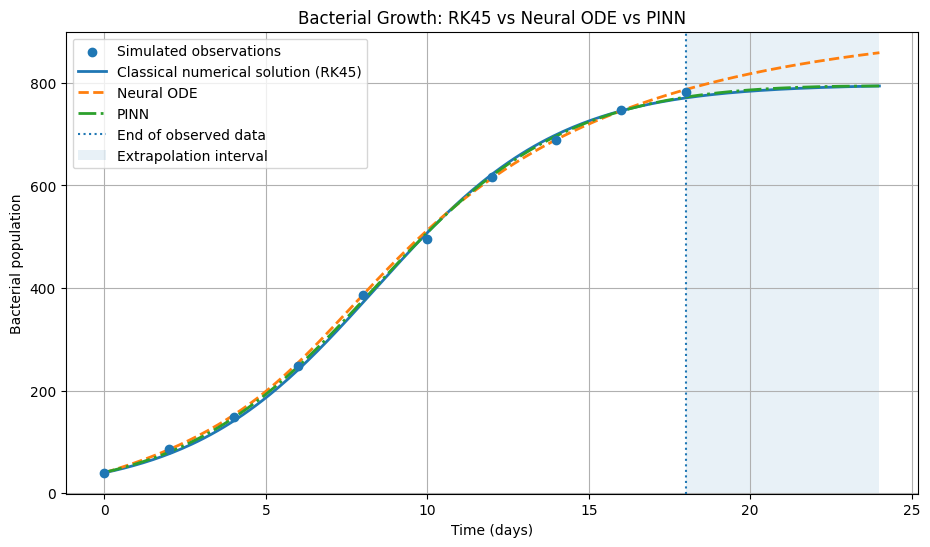

In [31]:
plt.figure(figsize=(11, 6))

# Simulated observations
plt.scatter(
    t_data,
    P_data,
    label="Simulated observations",
    zorder=5
)

# Classical numerical solution
plt.plot(
    t_eval_comparison,
    P_rk45,
    linewidth=2,
    label="Classical numerical solution (RK45)"
)

# Neural ODE
plt.plot(
    t_neural_comparison,
    P_neural_comparison,
    linestyle="--",
    linewidth=2,
    label="Neural ODE"
)

# PINN
plt.plot(
    t_comparison,
    P_pinn_prediction,
    linestyle="-.",
    linewidth=2,
    label="PINN"
)

# Mark the end of the observed-data interval
plt.axvline(
    18,
    linestyle=":",
    label="End of observed data"
)

plt.axvspan(
    18,
    24,
    alpha=0.10,
    label="Extrapolation interval"
)

plt.xlabel("Time (days)")
plt.ylabel("Bacterial population")
plt.title("Bacterial Growth: RK45 vs Neural ODE vs PINN")
plt.legend()
plt.grid()
plt.show()

### How should we interpret the comparison?

**RK45 numerical solution**

RK45 solves the specified logistic equation using an adaptive numerical integration method. It serves as our high-accuracy numerical reference.

**Neural ODE**

The Neural ODE learns a rate function from the observed trajectory. It may fit the observed data well, but its long-term behaviour is not automatically constrained to follow logistic growth.

**PINN**

The PINN approximates the population trajectory and is penalized when it violates the logistic equation. Because the physics residual is enforced up to day 24, the known differential equation guides its prediction beyond the observation interval.

A PINN is not automatically more accurate than a conventional solver. When the differential equation is already known and easy to solve, a conventional numerical solver is usually simpler and more efficient. PINNs become particularly interesting when data, unknown parameters, complex geometries or additional physical constraints make the problem more challenging.

## 12.12 Quantitative comparison

A graph is useful, but we also need numerical measures.

We will compare each model with the RK45 reference solution over the full interval from day 0 to day 24.

The trajectory RMSE is

$$
\boxed{\mathrm{RMSE}_{\mathrm{reference}}=
\sqrt{
\frac{1}{M}
\sum_{j=1}^{M}
\left[
P_{\mathrm{model}}(t_j)
-
P_{\mathrm{RK45}}(t_j)
\right]^2
}.
$$

We also calculate the RMSE at the observed data times. These two measures answer different questions:

- **Reference RMSE:** How closely does the model reproduce the fitted logistic trajectory over days 0–24?
- **Observation RMSE:** How closely does the model match the noisy observations from days 0–18?

The reference RMSE is not a measure of real-world biological accuracy. It measures agreement with the fitted logistic equation used in this demonstration.

In [32]:
# All comparison curves use 241 points on the same 0.1-day grid.
# Neural ODE and PINN grids both correspond to t = 0, 0.1, ..., 24.

# RMSE against the RK45 reference trajectory
rmse_neural_reference = np.sqrt(
    np.mean((P_neural_comparison - P_rk45) ** 2)
)

rmse_pinn_reference = np.sqrt(
    np.mean((P_pinn_prediction - P_rk45) ** 2)
)

rmse_euler_reference = np.sqrt(
    np.mean((
        np.interp(
            t_eval_comparison,
            *euler_method(r_est, K_est, P0, 0.5, 24)
        ) - P_rk45
    ) ** 2)
)

# Find indices corresponding to the observed times.
# The comparison grid is spaced every 0.1 day.
observation_indices = (t_data * 10).astype(int)

P_rk45_at_observations = P_rk45[observation_indices]
P_neural_at_observations = P_neural_comparison[observation_indices]
P_pinn_at_observations = P_pinn_prediction[observation_indices]

# RMSE against the noisy observations
rmse_rk45_data = np.sqrt(
    np.mean((P_rk45_at_observations - P_data) ** 2)
)

rmse_neural_data = np.sqrt(
    np.mean((P_neural_at_observations - P_data) ** 2)
)

rmse_pinn_data = np.sqrt(
    np.mean((P_pinn_at_observations - P_data) ** 2)
)

print("RMSE against RK45 reference, days 0 to 24")
print("------------------------------------------")
print(f"Neural ODE : {rmse_neural_reference:.4f}")
print(f"PINN       : {rmse_pinn_reference:.4f}")
print(f"Euler h=0.5: {rmse_euler_reference:.4f}")
print()
print("RMSE against noisy observations, days 0 to 18")
print("----------------------------------------------")
print(f"RK45       : {rmse_rk45_data:.4f}")
print(f"Neural ODE : {rmse_neural_data:.4f}")
print(f"PINN       : {rmse_pinn_data:.4f}")

RMSE against RK45 reference, days 0 to 24
------------------------------------------
Neural ODE : 23.8409
PINN       : 3.3905
Euler h=0.5: 13.9612

RMSE against noisy observations, days 0 to 18
----------------------------------------------
RK45       : 9.6154
Neural ODE : 6.0629
PINN       : 7.3396


## 12.13 Compare the predictions at day 24

The final population prediction is another useful comparison.

We compare the population predicted at day 24 by:

- RK45;
- Neural ODE;
- PINN.

The RK45 and PINN use the fitted logistic equation as known physics. The Neural ODE has learned its vector field from observations up to day 18.

In [33]:
print("Predicted bacterial population at day 24")
print("----------------------------------------")
print(f"RK45 numerical solution : {P_rk45[-1]:.2f}")
print(f"Neural ODE              : {P_neural_comparison[-1]:.2f}")
print(f"PINN                    : {P_pinn_prediction[-1]:.2f}")
print()
print("Difference from RK45 reference")
print("--------------------------------")
print(
    "Neural ODE:",
    f"{abs(P_neural_comparison[-1] - P_rk45[-1]):.2f}"
)
print(
    "PINN:",
    f"{abs(P_pinn_prediction[-1] - P_rk45[-1]):.2f}"
)

Predicted bacterial population at day 24
----------------------------------------
RK45 numerical solution : 793.84
Neural ODE              : 858.70
PINN                    : 793.88

Difference from RK45 reference
--------------------------------
Neural ODE: 64.86
PINN: 0.04


## 12.14 Inspect the PINN physics residual

A key feature of a PINN is that its solution should approximately satisfy the governing differential equation.

We can calculate the residual after training:

$$
\mathcal{R}_\theta(\tau)
=
\frac{dx_\theta}{d\tau}
-
T_s r_{\mathrm{est}}x_\theta
\left(1-\frac{Sx_\theta}{K_{\mathrm{est}}}\right).
$$

A residual close to zero indicates that the PINN approximately satisfies the normalized logistic equation.

The following graph shows the absolute residual across the time domain.

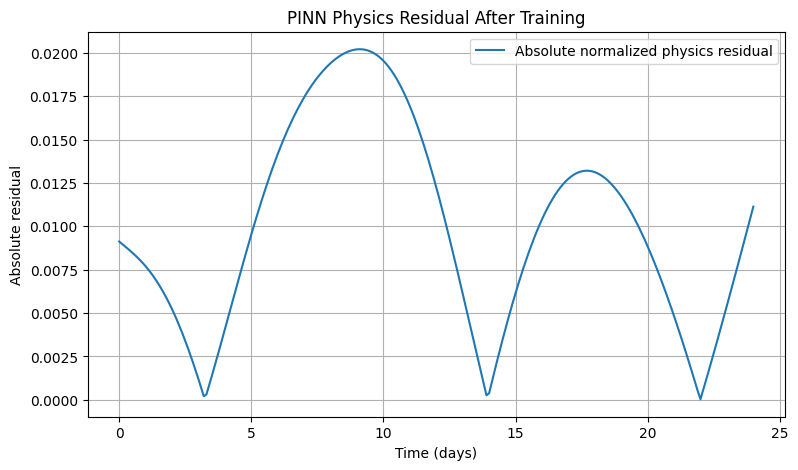

Mean absolute normalized residual: 0.00993481


In [34]:
# Create a fresh time tensor that requires gradients
tau_residual_check = torch.linspace(
    0.0, 2.4, 241
).reshape(-1, 1).requires_grad_(True)

# Calculate the trained PINN's physics residual
residual_check = pinn_physics_residual(
    pinn_model,
    tau_residual_check
)

absolute_residual = (
    residual_check.detach().numpy().flatten()
)

t_residual_check = (
    tau_residual_check.detach().numpy().flatten()
    * PINN_TIME_SCALE
)

plt.figure(figsize=(9, 5))

plt.plot(
    t_residual_check,
    np.abs(absolute_residual),
    label="Absolute normalized physics residual"
)

plt.xlabel("Time (days)")
plt.ylabel("Absolute residual")
plt.title("PINN Physics Residual After Training")
plt.legend()
plt.grid()
plt.show()

print(
    "Mean absolute normalized residual:",
    f"{np.mean(np.abs(absolute_residual)):.8f}"
)

## 12.15 Important scientific interpretation: Are the comparisons fair?

The three methods do not receive exactly the same information.

| Method | Information used |
|---|---|
| RK45 | The logistic equation and fitted values of $r$ and $K$ |
| Neural ODE | The observed population trajectory; it learns the rate function |
| PINN | The observed population trajectory, initial condition, logistic equation and fitted values of $r$ and $K$ |

This means the comparison is designed to teach the differences between the methods, not to declare one universally superior.

### Why might the PINN perform well here?

The PINN is given the correct form of the logistic equation and the fitted parameters. It therefore has strong mathematical guidance.

### Why might the Neural ODE extrapolate differently?

The Neural ODE is trained from the observations only. It does not explicitly know that the population should approach the logistic carrying capacity.

### Why is RK45 a strong baseline?

The logistic equation is already known, so a conventional numerical solver can integrate it directly and accurately. A neural network is not required to solve this simple forward problem.

### When are PINNs useful?

PINNs become more attractive when:

- The governing equation is known but analytical solutions are unavailable.
- Observations are sparse or noisy.
- Physical constraints can improve data-driven predictions.
- The problem involves unknown parameters or inverse modelling.
- Traditional numerical methods are difficult to apply in a particular setting.

For a simple logistic ODE, RK45 is generally the most straightforward solution. The value of the PINN demonstration is that it shows how physical laws can be incorporated into machine learning.

## 12.16 Optional research extension: Estimate the growth parameters inside the PINN

So far, the PINN uses $r_{\mathrm{est}}$ and $K_{\mathrm{est}}$ obtained from nonlinear least squares.

A more advanced inverse-PINN problem would treat the parameters as trainable quantities:

$$
r=r_\phi,
\qquad
K=K_\phi.
$$

The physics residual would then become

$$
\mathcal{R}_{\theta,\phi}(t)
=
\frac{dP_\theta}{dt}
-
r_\phi P_\theta
\left(1-\frac{P_\theta}{K_\phi}\right).
$$

The network weights and the physical parameters would be optimized together.

To ensure positive values, one could use transformations such as

$$
r_\phi=\operatorname{softplus}(a),
\qquad
K_\phi=P_0+\operatorname{softplus}(b),
$$

where $a$ and $b$ are unconstrained trainable parameters.

This is an inverse problem because the model uses observed data and the governing equation to estimate unknown physical parameters as well as the solution.

It is a suitable next research exercise, but it requires additional attention to parameter identifiability, loss balancing and uncertainty.

## 12.17 References for further reading

1. Raissi, M., Perdikaris, P., & Karniadakis, G. E. (2019). Physics-informed neural networks: A deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations. *Journal of Computational Physics, 378*, 686–707. https://doi.org/10.1016/j.jcp.2018.10.045

2. Chen, R. T. Q., Rubanova, Y., Bettencourt, J., & Duvenaud, D. (2018). Neural ordinary differential equations. *Advances in Neural Information Processing Systems, 31*. https://arxiv.org/abs/1806.07366

3. Rackauckas, C., et al. (2020). Universal differential equations for scientific machine learning. *arXiv*. https://arxiv.org/abs/2001.04385

---

# Student activities: Comparing Numerical ODEs, Neural ODEs and PINNs

### Activity 1: Change the PINN loss weights

Try different physics weights:

$$
\lambda_p=0.1,\quad 1,\quad 10.
$$

Questions:

1. How does the physics loss affect the predicted trajectory?
2. What happens when the physics weight is too small?
3. What happens when the physics weight is too large relative to the data loss?

### Activity 2: Change the number of collocation points

Try 25, 100, 241 and 500 collocation points.

Questions:

1. Does increasing the number of collocation points always improve the result?
2. How does the number of collocation points affect computational time?
3. Why is it important to distribute collocation points across the time domain?

### Activity 3: Remove the physics loss

Set $\lambda_p=0$ and retrain the PINN.

Questions:

1. How does the model behave when it is trained without the differential-equation constraint?
2. How does this differ from a standard data-fitting neural network?
3. Why is physical information valuable when observations are limited?

### Activity 4: Compare extrapolation

Train the Neural ODE only up to day 18, as before. Keep the PINN physics collocation domain up to day 24.

Questions:

1. Which model follows the logistic trajectory more closely after day 18?
2. What additional information does the PINN have?
3. Would the PINN still be reliable if the logistic model were incorrect?

### Activity 5: Research question

Suppose bacterial growth is affected by a sudden change in temperature on day 12.

Questions:

1. Would the original logistic model still be appropriate?
2. How could the differential equation be modified to include temperature?
3. How could a Neural ODE learn an unknown temperature-dependent growth effect?
4. How could a PINN incorporate known biological constraints while learning the unknown effect?

---

## Final conclusion

The same bacterial-growth problem can be studied using three different computational approaches.

- A **classical numerical solver** integrates a specified differential equation.
- A **Neural ODE** learns the rate of change from observations and integrates the learned dynamics.
- A **PINN** learns the solution while using the governing differential equation and initial condition as training constraints.

The most important distinction is how mathematical knowledge is used.

$$
\boxed{
\begin{aligned}
\text{Numerical ODE:}&\quad \text{Solve a specified equation}\\
\text{Neural ODE:}&\quad \text{Learn the dynamics from data}\\
\text{PINN:}&\quad \text{Learn a solution constrained by physics}
\end{aligned}
}
$$

This comparison demonstrates a central theme in modern scientific computing: combining numerical mathematics, differential equations, data and machine learning to understand dynamical systems.